# Notebook_A (Sinh viên A): dữ liệu, EDA, làm sạch, SQL, hình RQ1

**Đề tài**: Tải sạc xe điện nơi làm việc và đổi chế độ 2020 (ACN-Data, Caltech và JPL)

**Khung SDG**: SDG 7 và 11: sạc xe điện, giao thông bền vững; tiêu đề, keyword và abstract của bài dùng đúng cụm từ này.

**Vai trò**: Sinh viên A làm Bước 0 đến 3 và phần hình RQ1 của Bước 5, bàn giao `data/processed/feat.parquet` cùng `manifest.json` cho Sinh viên B (Notebook_B). Chạy tuần tự trong VS Code với extension Python và Jupyter, interpreter `.venv`. Mỗi bước có ô hướng dẫn *làm gì, vì sao, đọc thế nào* rồi đến ô code; mọi bảng lưu vào `report/` với tên `table_*.csv`, mọi hình `fig_*.png`.

**Quy tắc**: seed 42; không xoá dòng mà không ghi lý do; mọi prompt AI ghi vào Audit Log cá nhân; báo cáo slot 3 thứ Tư và thứ Bảy (12:30 đến 14:45) theo mẫu ở ô cuối.

## Vừa làm vừa hỏi AI và ghi Audit Log: cách làm nhẹ nhàng, không rối

**Tinh thần**: AI là bạn cùng làm, không phải người làm thay. Bạn được hỏi AI bất cứ lúc nào; điều duy nhất phải giữ là *kiểm tra một lần* trước khi dùng và *ghi lại 2 phút* nếu câu hỏi đó thay đổi việc bạn làm.

**Khi nào hỏi AI** (theo thứ tự):
1. Đọc ô hướng dẫn của bước đang làm (1 phút).
2. Thử tự làm 15 phút.
3. Bí quá 15 phút thì hỏi AI với mẫu: *"Tôi đang làm Bước X của dự án Y. Dữ liệu có cột A, B, C. Tôi muốn Z. Đây là code và lỗi: ... Hãy giải thích nguyên nhân và sửa, giữ nguyên tên biến."*
4. Chạy thử code AI đưa trên dữ liệu thật; so một con số bằng tay hoặc bằng cách thứ hai.
5. Nếu vẫn bí sau 30 phút, ghi lại lỗi và hỏi giảng viên ở kênh nhóm.

**Ghi Audit Log thế nào cho không áp lực**: chỉ ghi các prompt *đã thay đổi việc bạn làm* (thường 3 đến 5 prompt một tuần, 15 đến 20 cả kỳ). Mỗi dòng 5 ô, điền trong 2 phút ngay khi dùng, không để cuối tuần:

| Ngày, bước | Prompt (rút gọn) | AI trả lời gì (1 dòng) | Tôi kiểm tra hoặc sửa gì | Dùng vào đâu |
|---|---|---|---|---|
| 09/09, Bước 3 | viết truy vấn trung bình trượt 7 ngày theo trạm | đưa AVG OVER ROWS 6 PRECEDING | thiếu PARTITION BY site_num, thêm và thử 2 trạm | Q3 trong sql/queries.sql |

Cột thứ tư chính là *Human Delta* và là thứ hội đồng hỏi; ghi thật, kể cả khi AI đúng ("kiểm tra bằng 10 dòng tính tay, khớp"). Ba lần bạn phát hiện AI sai trong cả kỳ là đủ yêu cầu.

**Nhịp làm việc**: mỗi ngày 1,5 đến 2 giờ vào đúng bước của tuần, xong một ô thì commit; thứ Ba và thứ Sáu slot 1 báo cáo năm mục đúng tiến độ, dù kết quả chưa đẹp. Siêng và đúng nhịp quan trọng hơn giỏi: nhóm báo cáo đều 6 lần trong 3 tuần luôn có bài, nhóm im lặng đến tuần 3 thường không kịp.

## Bước 0: môi trường và cấu trúc thư mục

Chạy một lần trong Terminal của VS Code, không phải trong ô Python. Sau khi cài xong chọn interpreter `.venv` (Ctrl+Shift+P, *Python: Select Interpreter*).

```bash
# Step 1a: environment and project layout (run once)
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost catboost \
    statsmodels shap matplotlib seaborn ydata-profiling mapie jupyter
pip freeze > requirements.txt
mkdir -p data/raw data/processed notebooks sql src report
printf "data/raw\ndata/processed\n.venv\n*.parquet\n" > .gitignore
```

In [1]:
# Environment check and shared imports for the whole notebook
import pandas as pd, numpy as np, duckdb, matplotlib
import matplotlib.pyplot as plt, pathlib, warnings
warnings.filterwarnings('ignore')
for d in ['data/raw', 'data/processed', 'notebooks', 'sql', 'src', 'report']: pathlib.Path(d).mkdir(parents=True, exist_ok=True)
np.random.seed(42); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
print('pandas', pd.__version__, '| duckdb', duckdb.__version__)

pandas 2.3.3 | duckdb 1.5.5


## Vì sao sáu bước và mỗi bước giúp gì cho bài

| Bước | Mục đích | Lợi ích cho bài | Bằng chứng, câu hỏi |
|---|---|---|---|
| 1 Nạp, hiểu dữ liệu | biết quy mô, thời gian, đơn vị, mục tiêu | bảng mô tả dữ liệu, phạm vi hợp lệ | table_describe, profile; nền mọi RQ |
| 2 Làm sạch, ghép | dữ liệu tin được, có nguồn thứ hai | nhật ký làm sạch trả lời phản biện; đặc trưng ngoại sinh | cleaning_log, tỷ lệ khớp; RQ1, RQ2 |
| 3 SQL, EDA | trả lời câu hỏi mô tả bằng số có kiểm định; đặc trưng đúng thời điểm | bảng RQ1 có p-value; không rò rỉ; điểm SQL | table_q*, rq1a-c; RQ1 |
| 4 Chia dữ liệu | đánh giá công bằng | mốc naive cho biết cải thiện thật | table_features; RQ2 |
| 5 Trực quan hoá | thấy cấu trúc và bất thường; truyền đạt | hình có caption kết luận | fig_rq1_*; RQ1 |
| 6 Mô hình, RQ3 | so năm mô hình công bằng; đóng góp chính | bảng có độ lệch, tinh chỉnh có căn cứ, SHAP | table_rq2, rq3; RQ2, RQ3 |

**Vì sao phải chọn cột từ nhiều cột**: cột thừa làm mô hình học nhiễu, cột chứa giá trị tương lai làm kết quả đẹp giả, cột không có lúc vận hành làm mô hình vô dụng. Bốn bước giúp chọn đúng cột và khớp RQ: (1) tài liệu cơ quan cho biết ý nghĩa vật lý; (2) bảng thiếu và bảng tương quan trong EDA loại cột thiếu nhiều hoặc trùng; (3) SQL với LAG/LEAD tách quá khứ khỏi tương lai; (4) SHAP sau mô hình xác nhận cột thực sự đóng góp. Mỗi cột giữ lại phải nối về một RQ: cột mô tả cho RQ1, cột dự báo cho RQ2, cột nhóm hoặc điều kiện cho RQ3.

## Bước 1: hiểu bài toán và nạp dữ liệu

### 1.1. Bài toán và ba câu hỏi

Ghi lại ở đây ba câu hỏi nghiên cứu của đề cương (RQ1 mô tả, RQ2 mô hình, RQ3 câu hỏi thứ ba) và biến mục tiêu; mọi bảng và hình sau này phải nối về một trong ba câu hỏi.

**Làm gì**: tải file gốc từ trang cơ quan vào `data/raw/`, nạp bằng DuckDB (đọc thẳng file từ đĩa, chỉ lấy cột và dòng cần) rồi in số dòng, số cột, khoảng thời gian, số đơn vị.

**Kiểm tra**: `df.shape` khớp tài liệu cơ quan; khoảng thời gian đúng; số đơn vị đúng phạm vi đề cương.

In [2]:
import pandas as pd
import requests
import time
from pathlib import Path
from urllib.parse import quote

# ============================================================
# CONFIG
# ============================================================

TOKEN = "t0_5pmJQkCYqF0PxUKjZviunNzqk8pPtZMObZr42nXw"

SITES = ["caltech", "jpl"]

START = "2018-01-01"
END   = "2022-01-01"

MAX_RETRIES = 5
TIMEOUT = 120

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

MONTH_DIR = Path("data/checkpoints_monthly")
MONTH_DIR.mkdir(parents=True, exist_ok=True)

FINAL_FILE = RAW_DIR / "acn_sessions_raw.csv"

http = requests.Session()


# ============================================================
# DOWNLOAD ONE MONTH
# ============================================================

def download_month(site, start_date, end_date):

    month_name = start_date.strftime("%Y-%m")

    checkpoint = (
        MONTH_DIR /
        f"{site}_{month_name}.csv"
    )

    # Nếu tháng này tải rồi -> dùng lại
    if checkpoint.exists():

        old = pd.read_csv(checkpoint)

        print(
            f"✅ {site} {month_name}: "
            f"đã có {len(old):,} rows"
        )

        return old


    print(
        f"\n===== {site} | {month_name} ====="
    )


    # ACN API dùng RFC-style date strings.
    start_str = start_date.strftime(
        "%a, %d %b %Y 00:00:00 GMT"
    )

    end_str = end_date.strftime(
        "%a, %d %b %Y 00:00:00 GMT"
    )


    where = (
        f'connectionTime>="{start_str}" '
        f'and connectionTime<"{end_str}"'
    )


    page = 1

    rows = []


    while True:

        params = {
            "where": where,
            "page": page
        }


        success = False
        js = None


        for attempt in range(
            1,
            MAX_RETRIES + 1
        ):

            try:

                print(
                    f"{site} {month_name} "
                    f"| page={page} "
                    f"| try={attempt}/{MAX_RETRIES}"
                )


                r = http.get(
                    f"https://ev.caltech.edu/api/v1/sessions/{site}",
                    params=params,
                    auth=(TOKEN, ""),
                    timeout=TIMEOUT
                )


                print(
                    "HTTP:",
                    r.status_code
                )


                if r.status_code in [
                    401,
                    403
                ]:

                    raise RuntimeError(
                        "Token sai hoặc không có quyền."
                    )


                if r.status_code in [
                    500,
                    502,
                    503,
                    504
                ]:

                    raise requests.exceptions.RequestException(
                        f"Server error {r.status_code}"
                    )


                r.raise_for_status()


                js = r.json()


                success = True
                break


            except Exception as e:

                print(
                    "⚠️",
                    e
                )


                if attempt < MAX_RETRIES:

                    wait = min(
                        attempt * 5,
                        20
                    )

                    print(
                        f"Chờ {wait}s..."
                    )

                    time.sleep(wait)


        # Nếu tháng này lỗi quá nhiều lần
        if not success:

            print(
                f"⏸ Tạm dừng {site} {month_name} "
                f"tại page {page}"
            )

            return None


        items = js.get(
            "_items",
            []
        )


        if len(items) == 0:

            break


        for it in items:

            rows.append({

                "site":
                    site,

                "session_id":
                    it.get("_id"),

                "start":
                    it.get("connectionTime"),

                "end":
                    it.get("disconnectTime"),

                "done":
                    it.get("doneChargingTime"),

                "kwh":
                    it.get("kWhDelivered"),

                "station":
                    it.get("stationID"),

                "user":
                    it.get("userID")

            })


        # Cách chuẩn hơn:
        # nếu API không có next link -> hết dữ liệu
        links = js.get(
            "_links",
            {}
        )


        if "next" not in links:

            break


        page += 1

        # Delay ngắn thôi
        time.sleep(0.5)


    # ========================================================
    # SAVE MONTH
    # ========================================================

    month_df = pd.DataFrame(
        rows
    )


    if len(month_df) > 0:

        month_df = month_df.drop_duplicates(
            subset=["session_id"]
        )


    month_df.to_csv(
        checkpoint,
        index=False
    )


    print(
        f"✅ {site} {month_name}: "
        f"{len(month_df):,} sessions"
    )


    return month_df


# ============================================================
# BUILD MONTH RANGE
# ============================================================

months = pd.date_range(
    START,
    END,
    freq="MS"
)


all_parts = []


# ============================================================
# DOWNLOAD
# ============================================================

for site in SITES:

    for i in range(
        len(months) - 1
    ):

        start_date = months[i]
        end_date = months[i + 1]

        month_df = download_month(
            site,
            start_date,
            end_date
        )


        if month_df is not None:

            all_parts.append(
                month_df
            )


# ============================================================
# CONCAT
# ============================================================

if len(all_parts) == 0:

    raise RuntimeError(
        "Không tải được dữ liệu."
    )


df = pd.concat(
    all_parts,
    ignore_index=True
)


df = df.drop_duplicates(
    subset=["session_id"]
)


# ============================================================
# DATETIME
# ============================================================

for col in [
    "start",
    "end",
    "done"
]:

    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        utc=True
    )


df["kwh"] = pd.to_numeric(
    df["kwh"],
    errors="coerce"
)


# ============================================================
# FILTER FINAL RANGE
# ============================================================

df = df[
    (df["start"] >= "2018-01-01") &
    (df["start"] < "2022-01-01")
].copy()


df = df.sort_values(
    [
        "site",
        "start"
    ]
).reset_index(
    drop=True
)


# ============================================================
# SAVE
# ============================================================

df.to_csv(
    FINAL_FILE,
    index=False
)


# ============================================================
# RESULT
# ============================================================

print("\n==============================")
print("STEP 1b DONE")
print("==============================")


print(
    "Shape:",
    df.shape
)


print(
    "Sites:"
)

print(
    df["site"]
    .value_counts()
)


print(
    "Date range:"
)

print(
    df["start"].min(),
    "->",
    df["start"].max()
)


print(
    "Stations:",
    df["station"].nunique()
)


print(
    "Duplicate:",
    df["session_id"]
    .duplicated()
    .sum()
)


print(
    "Saved:",
    FINAL_FILE
)

EmptyDataError: No columns to parse from file

kiểm tra chất lượng

In [ ]:
print("===== BASIC QUALITY CHECK =====")

print("\nShape:")
print(df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nMissing percentage:")
print(
    (df.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nDuplicate session_id:")
print(df["session_id"].duplicated().sum())

print("\nkWh <= 0:")
print((df["kwh"] <= 0).sum())

print("\nend <= start:")
print((df["end"] <= df["start"]).sum())

print("\nMissing start:")
print(df["start"].isna().sum())

print("\nMissing end:")
print(df["end"].isna().sum())

print("\nMissing kwh:")
print(df["kwh"].isna().sum())

print("\nUnique stations:")
print(df["station"].nunique())

print("\nSessions by site:")
print(df["site"].value_counts())

print("\nDate range:")
print(df["start"].min())
print(df["start"].max())

===== BASIC QUALITY CHECK =====

Shape:
(65062, 8)

Missing values:
site              0
session_id        0
start             0
end               0
done           4092
kwh               0
station           0
user          17215
dtype: int64

Missing percentage:
user          26.46
done           6.29
site           0.00
session_id     0.00
end            0.00
start          0.00
kwh            0.00
station        0.00
dtype: float64

Duplicate session_id:
0

kWh <= 0:
0

end <= start:
0

Missing start:
0

Missing end:
0

Missing kwh:
0

Unique stations:
107

Sessions by site:
site
jpl        33638
caltech    31424
Name: count, dtype: int64

Date range:
2018-04-25 11:08:04+00:00
2021-09-14 05:43:39+00:00


### 1.1b. Hồ sơ tự động

`ydata-profiling` trên mẫu 20 nghìn dòng tạo `report/profile.html`; mở bằng trình duyệt để xem nhanh phân phối, thiếu, tương quan trước khi tự viết EDA ở các ô sau.

In [ ]:
import sys
!{sys.executable} -m pip install ydata-profiling


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path
from ydata_profiling import ProfileReport

Path("report").mkdir(parents=True, exist_ok=True)

sample = df.sample(
    min(20000, len(df)),
    random_state=42
)

ProfileReport(
    sample,
    minimal=True
).to_file(
    "report/profile.html"
)

df.describe(
    include="all"
).T.to_csv(
    "report/table_describe_raw.csv"
)

print("✅ Đã tạo:")
print("report/profile.html")
print("report/table_describe_raw.csv")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:02<00:00,  3.58it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Đã tạo:
report/profile.html
report/table_describe_raw.csv


In [ ]:
from pathlib import Path

print("Thư mục hiện tại:")
print(Path.cwd())

print("\nprofile.html:")
print((Path("report") / "profile.html").resolve())

print("\ntable_describe_raw.csv:")
print((Path("report") / "table_describe_raw.csv").resolve())

Thư mục hiện tại:
c:\Users\ASUS\Downloads

profile.html:
C:\Users\ASUS\Downloads\report\profile.html

table_describe_raw.csv:
C:\Users\ASUS\Downloads\report\table_describe_raw.csv


## Bước 2: hiểu dữ liệu và làm sạch, ghép nguồn thứ hai

**Làm gì**: chuẩn tên cột; bỏ trùng theo khoá; bỏ thiếu ở biến mục tiêu; loại giá trị ngoài khoảng vật lý theo tài liệu cơ quan; dựng khoá thời gian đầy đủ và nội suy ngắn; ghép nguồn thứ hai; lưu parquet.

**Kiểm tra**: số dòng sau merge không tăng; tỷ lệ khớp trên 90%; ghi số dòng bỏ ở mỗi bước vào nhật ký làm sạch (ô sau).

In [ ]:
from pathlib import Path #thử file có tồn tại không

ACN_FILE = Path(
    r"G:\My Drive\Group11_ADY201m_FA26_AI2107"
)

PASADENA_FILE = Path(
    
    r"g:\My Drive\Group11_ADY201m_FA26_AI2107\pasadena"
)

CAISO_DIR = Path(
    r"G:\My Drive\Group11_ADY201m_FA26_AI2107\caiso"
)

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("ACN exists:", ACN_FILE.exists())
print("Pasadena exists:", PASADENA_FILE.exists())
print("CAISO exists:", CAISO_DIR.exists())

ACN exists: True
Pasadena exists: True
CAISO exists: True


In [ ]:
print("Tổng ZIP CAISO:", len(zip_files))
print("ZIP dùng cho ACN:", len(selected_zips))

print(
    "ACN date:",
    min_date,
    "->",
    max_date
)

Tổng ZIP CAISO: 1461
ZIP dùng cho ACN: 1239
ACN date: 2018-04-25 -> 2021-09-14


In [ ]:
# ============================================================
# STEP 2
# CLEAN ACN -> HOURLY -> PASADENA + CAISO -> PARQUET
# Windows + VS Code + Google Drive for Desktop
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import time
import re
import gc

# ============================================================
# 0. PATHS
# ============================================================

# ACN tạo từ Step 1b, nằm trên máy local
ACN_FILE = Path(
    r"data\raw\acn_sessions_raw.csv"
)

# Google Drive for Desktop
BASE_DRIVE = Path(
    r"G:\My Drive\Group11_ADY201m_FA26_AI2107"
)

PASADENA_DIR = Path(
    r"G:\My Drive\Group11_ADY201m_FA26_AI2107\pasadena"
)

CAISO_DIR = Path(
    r"G:\My Drive\Group11_ADY201m_FA26_AI2107\caiso"
)

# Local output
OUTPUT_DIR = Path("data/processed")
REPORT_DIR = Path("report")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

PASADENA_HOURLY_FILE = OUTPUT_DIR / "pasadena_hourly.csv"
CAISO_HOURLY_FILE = OUTPUT_DIR / "caiso_price_hourly.csv"

FINAL_FILE = OUTPUT_DIR / "acn.parquet"
CLEAN_LOG_FILE = REPORT_DIR / "table_cleaning_log.csv"


# ============================================================
# 1. CHECK PATHS
# ============================================================

print("========================================")
print("1. FILE CHECK")
print("========================================")

print("ACN:", ACN_FILE.exists(), ACN_FILE)
print("Pasadena:", PASADENA_DIR.exists(), PASADENA_DIR)
print("CAISO:", CAISO_DIR.exists(), CAISO_DIR)

if not ACN_FILE.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy ACN file:\n{ACN_FILE}"
    )

if not PASADENA_DIR.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy Pasadena folder:\n{PASADENA_DIR}"
    )

if not CAISO_DIR.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy CAISO folder:\n{CAISO_DIR}"
    )


# ============================================================
# 2. LOAD ACN
# ============================================================

print("\n========================================")
print("2. LOAD ACN")
print("========================================")

df = pd.read_csv(
    ACN_FILE,
    low_memory=False
)

# Chuẩn hóa tên cột
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

required = {
    "site",
    "session_id",
    "start",
    "end",
    "kwh"
}

missing = required - set(df.columns)

if missing:
    raise ValueError(
        f"ACN thiếu các cột: {missing}"
    )

# Datetime
for col in ["start", "end", "done"]:
    if col in df.columns:
        df[col] = pd.to_datetime(
            df[col],
            errors="coerce",
            utc=True
        )

df["kwh"] = pd.to_numeric(
    df["kwh"],
    errors="coerce"
)

print("Raw shape:", df.shape)
print("Date:", df["start"].min(), "->", df["start"].max())


# ============================================================
# 3. CLEANING LOG
# ============================================================

clean_log = []


def log_clean(step, before, after, reason):

    clean_log.append({
        "step": step,
        "rows_before": before,
        "rows_after": after,
        "rows_removed": before - after,
        "reason": reason
    })


# ============================================================
# 4. REMOVE DUPLICATE SESSION_ID
# ============================================================

before = len(df)

df = (
    df
    .drop_duplicates(
        subset=["session_id"]
    )
    .copy()
)

log_clean(
    "Remove duplicate session_id",
    before,
    len(df),
    "session_id is the unique session key"
)


# ============================================================
# 5. REMOVE MISSING REQUIRED VALUES
# ============================================================

before = len(df)

df = df.dropna(
    subset=[
        "start",
        "end",
        "kwh"
    ]
).copy()

log_clean(
    "Drop missing start/end/kwh",
    before,
    len(df),
    "Required to construct hourly charging load"
)


# ============================================================
# 6. REMOVE INVALID PHYSICAL VALUES
# ============================================================

before = len(df)

df = df[
    (df["kwh"] > 0) &
    (df["end"] > df["start"])
].copy()

log_clean(
    "Remove invalid sessions",
    before,
    len(df),
    "Require kwh > 0 and end > start"
)

print("\nCleaning result:")
print(pd.DataFrame(clean_log).to_string(index=False))


# ============================================================
# 7. ACN: UTC -> CALIFORNIA LOCAL TIME
# ============================================================

# ACN API data đang UTC.
# Pasadena là local California.
# Vì vậy đổi ACN về America/Los_Angeles trước khi merge.

df["start_local"] = (
    df["start"]
    .dt
    .tz_convert("America/Los_Angeles")
)

df["end_local"] = (
    df["end"]
    .dt
    .tz_convert("America/Los_Angeles")
)


# ============================================================
# 8. SESSION -> HOURLY
# ============================================================

print("\n========================================")
print("3. ACN SESSION -> HOURLY")
print("========================================")

hour_rows = []

total_sessions = len(df)

for i, r in enumerate(
    df.itertuples(),
    start=1
):

    start = pd.Timestamp(r.start_local)
    end = pd.Timestamp(r.end_local)

    hrs = pd.date_range(
        start.floor("h"),
        end.floor("h"),
        freq="h"
    )

    if len(hrs) == 0:
        continue

    # Giữ đúng logic notebook gốc:
    # chia đều session kWh cho các giờ session đi qua
    share = r.kwh / len(hrs)

    for hh in hrs:

        # Xóa timezone SAU KHI đã convert sang California
        hh = hh.tz_localize(None)

        hour_rows.append(
            (
                r.site,
                hh,
                share,
                r.session_id
            )
        )

    if i % 10000 == 0:
        print(
            f"{i:,}/{total_sessions:,} sessions"
        )


expanded = pd.DataFrame(
    hour_rows,
    columns=[
        "site",
        "ts",
        "kwh",
        "session_id"
    ]
)

print(
    "Expanded rows:",
    f"{len(expanded):,}"
)


# ============================================================
# 9. AGGREGATE SITE-HOUR
# ============================================================

h = (
    expanded
    .groupby(
        ["site", "ts"],
        as_index=False
    )
    .agg(
        kwh=(
            "kwh",
            "sum"
        ),
        sessions=(
            "session_id",
            "nunique"
        )
    )
)

print(
    "Observed site-hours:",
    f"{len(h):,}"
)


# ============================================================
# 10. BUILD COMPLETE HOURLY TIME KEY
# ============================================================

full_parts = []

for site, g in h.groupby("site"):

    g = (
        g
        .set_index("ts")
        .sort_index()
    )

    timeline = pd.date_range(
        start=g.index.min(),
        end=g.index.max(),
        freq="h"
    )

    g = g.reindex(
        timeline
    )

    g.index.name = "ts"

    # Không có session trong giờ đó
    g["kwh"] = g["kwh"].fillna(0)
    g["sessions"] = g["sessions"].fillna(0)

    g["site"] = site

    full_parts.append(
        g.reset_index()
    )


full = pd.concat(
    full_parts,
    ignore_index=True
)

full = full[
    [
        "site",
        "ts",
        "kwh",
        "sessions"
    ]
]

print(
    "Complete site-hour table:",
    full.shape
)

print(
    "Hourly range:",
    full["ts"].min(),
    "->",
    full["ts"].max()
)

del expanded
del hour_rows
gc.collect()


# ============================================================
# 11. PASADENA WEATHER
# ============================================================

print("\n========================================")
print("4. PASADENA WEATHER")
print("========================================")

pasadena_files = sorted(
    PASADENA_DIR.glob("*.csv")
)

print(
    "Pasadena CSV files:",
    len(pasadena_files)
)

if len(pasadena_files) == 0:
    raise FileNotFoundError(
        "Folder Pasadena không có CSV."
    )


weather_parts = []

for file in pasadena_files:

    print("Reading:", file.name)

    w = pd.read_csv(
        file,
        low_memory=False
    )

    # Trường hợp đã chuẩn hóa
    if {
        "ts",
        "temp"
    }.issubset(w.columns):

        temp = w[
            ["ts", "temp"]
        ].copy()

    # NOAA raw
    elif {
        "DATE",
        "HourlyDryBulbTemperature"
    }.issubset(w.columns):

        temp = w[
            [
                "DATE",
                "HourlyDryBulbTemperature"
            ]
        ].copy()

        temp.columns = [
            "ts",
            "temp"
        ]

    else:

        print(
            "⚠️ Skip - missing required weather columns:",
            file.name
        )

        continue


    temp["ts"] = pd.to_datetime(
        temp["ts"],
        errors="coerce"
    )

    # NOAA temperature đôi khi có ký tự phụ
    temp["temp"] = (
        temp["temp"]
        .astype(str)
        .str.extract(
            r"(-?\d+(?:\.\d+)?)"
        )[0]
    )

    temp["temp"] = pd.to_numeric(
        temp["temp"],
        errors="coerce"
    )

    temp = temp.dropna(
        subset=["ts", "temp"]
    )

    weather_parts.append(
        temp
    )


if len(weather_parts) == 0:
    raise RuntimeError(
        "Không đọc được Pasadena weather."
    )


wx = pd.concat(
    weather_parts,
    ignore_index=True
)

wx["ts"] = (
    pd.to_datetime(
        wx["ts"],
        errors="coerce"
    )
    .dt
    .floor("h")
)

# Một giờ có nhiều observation -> mean
wx = (
    wx
    .dropna(
        subset=["ts"]
    )
    .groupby(
        "ts",
        as_index=False
    )["temp"]
    .mean()
    .sort_values("ts")
    .reset_index(drop=True)
)

# Chỉ giữ phạm vi liên quan ACN
wx = wx[
    (wx["ts"] >= full["ts"].min()) &
    (wx["ts"] <= full["ts"].max())
].copy()


# ------------------------------------------------------------
# SHORT-GAP INTERPOLATION
# max 3 consecutive hours
# ------------------------------------------------------------

wx = (
    wx.set_index("ts")
      .reindex(
          pd.date_range(
              wx["ts"].min(),
              wx["ts"].max(),
              freq="h"
          )
      )
)

wx.index.name = "ts"

weather_missing_before = (
    wx["temp"].isna().sum()
)

wx["temp"] = wx["temp"].interpolate(
    limit=3,
    limit_direction="both"
)

weather_missing_after = (
    wx["temp"].isna().sum()
)

wx = wx.reset_index()


wx.to_csv(
    PASADENA_HOURLY_FILE,
    index=False
)

print(
    "Weather rows:",
    len(wx)
)

print(
    "Weather range:",
    wx["ts"].min(),
    "->",
    wx["ts"].max()
)

print(
    "Weather missing before short interpolation:",
    weather_missing_before
)

print(
    "Weather missing after short interpolation:",
    weather_missing_after
)

print(
    "Saved:",
    PASADENA_HOURLY_FILE
)


# ============================================================
# 12. CAISO
# ============================================================

print("\n========================================")
print("5. CAISO")
print("========================================")

CAISO_NODE = "TH_SP15_GEN-APND"

zip_files = sorted(
    CAISO_DIR.glob("*.zip")
)

print(
    "All CAISO ZIP:",
    len(zip_files)
)

if len(zip_files) == 0:
    raise FileNotFoundError(
        "CAISO folder không có ZIP."
    )


# ------------------------------------------------------------
# Chỉ lấy ZIP nằm trong ACN date range
# giảm thời gian chạy
# ------------------------------------------------------------

min_date = full["ts"].min().date()
max_date = full["ts"].max().date()


def zip_date(path):

    match = re.match(
        r"(\d{8})",
        path.name
    )

    if not match:
        return None

    return pd.to_datetime(
        match.group(1),
        format="%Y%m%d",
        errors="coerce"
    )


selected_zips = []

for z in zip_files:

    d = zip_date(z)

    if d is None or pd.isna(d):
        continue

    if (
        d.date() >= min_date
        and
        d.date() <= max_date
    ):
        selected_zips.append(z)


print(
    "ZIP overlapping ACN:",
    len(selected_zips)
)


caiso_parts = []
bad_zips = []


for i, zip_path in enumerate(
    selected_zips,
    start=1
):

    if (
        i == 1
        or i % 50 == 0
        or i == len(selected_zips)
    ):

        print(
            f"{i}/{len(selected_zips)}",
            zip_path.name
        )


    success = False


    # Retry giúp Drive streaming ổn định hơn
    for attempt in range(1, 4):

        try:

            with zipfile.ZipFile(
                zip_path,
                "r"
            ) as zf:

                targets = [
                    name
                    for name in zf.namelist()
                    if (
                        name.lower().endswith(".csv")
                        and
                        "_PRC_LMP_DAM_LMP_" in name
                    )
                ]


                if not targets:
                    break


                target = targets[0]


                with zf.open(
                    target
                ) as f:

                    # Chỉ đọc đúng cột cần thiết
                    c = pd.read_csv(
                        f,
                        usecols=[
                            "INTERVALSTARTTIME_GMT",
                            "NODE_ID",
                            "LMP_TYPE",
                            "MW"
                        ],
                        low_memory=False
                    )


            # Giữ SP15 node
            c = c[
                c["NODE_ID"]
                .astype(str)
                .str.strip()
                .eq(CAISO_NODE)
            ].copy()


            # Giữ total LMP
            c = c[
                c["LMP_TYPE"]
                .astype(str)
                .str.upper()
                .str.strip()
                .eq("LMP")
            ].copy()


            if len(c) > 0:

                c["price"] = pd.to_numeric(
                    c["MW"],
                    errors="coerce"
                )


                ts = pd.to_datetime(
                    c["INTERVALSTARTTIME_GMT"],
                    errors="coerce",
                    utc=True
                )


                # UTC -> California local
                c["ts"] = (
                    ts
                    .dt
                    .tz_convert(
                        "America/Los_Angeles"
                    )
                    .dt
                    .tz_localize(None)
                    .dt
                    .floor("h")
                )


                c = c[
                    ["ts", "price"]
                ].dropna()


                caiso_parts.append(
                    c
                )


            success = True
            break


        except Exception as e:

            if attempt < 3:

                print(
                    f"⚠️ Retry {zip_path.name}:",
                    e
                )

                time.sleep(
                    attempt * 3
                )

            else:

                bad_zips.append({
                    "file": zip_path.name,
                    "error": str(e)
                })


if len(caiso_parts) == 0:

    raise RuntimeError(
        "Không lấy được CAISO data."
    )


pr = pd.concat(
    caiso_parts,
    ignore_index=True
)

pr = (
    pr
    .groupby(
        "ts",
        as_index=False
    )["price"]
    .mean()
    .sort_values("ts")
    .reset_index(drop=True)
)


pr.to_csv(
    CAISO_HOURLY_FILE,
    index=False
)


print(
    "CAISO rows:",
    len(pr)
)

print(
    "CAISO range:",
    pr["ts"].min(),
    "->",
    pr["ts"].max()
)

print(
    "Bad ZIP count:",
    len(bad_zips)
)

print(
    "Saved:",
    CAISO_HOURLY_FILE
)


if bad_zips:

    pd.DataFrame(
        bad_zips
    ).to_csv(
        REPORT_DIR /
        "table_caiso_bad_zip.csv",
        index=False
    )


del caiso_parts
gc.collect()


# ============================================================
# 13. PRE-MERGE KEY CHECK
# ============================================================

print("\n========================================")
print("6. MERGE VALIDATION")
print("========================================")

print(
    "Duplicate full site-ts:",
    full.duplicated(
        ["site", "ts"]
    ).sum()
)

print(
    "Duplicate weather ts:",
    wx["ts"].duplicated().sum()
)

print(
    "Duplicate CAISO ts:",
    pr["ts"].duplicated().sum()
)


if wx["ts"].duplicated().any():

    raise RuntimeError(
        "Pasadena ts còn duplicate."
    )


if pr["ts"].duplicated().any():

    raise RuntimeError(
        "CAISO ts còn duplicate."
    )


# ============================================================
# 14. MERGE WEATHER
# ============================================================

rows_before_merge = len(full)

full = full.merge(
    wx,
    on="ts",
    how="left",
    validate="many_to_one"
)


if len(full) != rows_before_merge:

    raise RuntimeError(
        "Weather merge làm thay đổi số dòng."
    )


weather_match = (
    full["temp"]
    .notna()
    .mean()
)


# ============================================================
# 15. MERGE CAISO
# ============================================================

full = full.merge(
    pr,
    on="ts",
    how="left",
    validate="many_to_one"
)


if len(full) != rows_before_merge:

    raise RuntimeError(
        "CAISO merge làm thay đổi số dòng."
    )


price_match = (
    full["price"]
    .notna()
    .mean()
)


print(
    f"Weather match: {weather_match:.2%}"
)

print(
    f"CAISO match:   {price_match:.2%}"
)


# ============================================================
# 16. REQUIRE > 90% MATCH
# ============================================================

if weather_match < 0.90:

    print(
        "⚠️ Weather match < 90%."
    )

else:

    print(
        "✅ Weather match >= 90%"
    )


if price_match < 0.90:

    print(
        "⚠️ CAISO match < 90%."
    )

else:

    print(
        "✅ CAISO match >= 90%"
    )


# ============================================================
# 17. FINAL QUALITY
# ============================================================

print("\n========================================")
print("7. FINAL QUALITY")
print("========================================")

duplicate_final = (
    full
    .duplicated(
        ["site", "ts"]
    )
    .sum()
)


print(
    "Final shape:",
    full.shape
)

print(
    "Columns:",
    full.columns.tolist()
)

print(
    "Duplicate site-ts:",
    duplicate_final
)

print(
    "\nMissing values:"
)

print(
    full.isna().sum()
)


if duplicate_final != 0:

    raise RuntimeError(
        "Final data có duplicate site-ts."
    )


# ============================================================
# 18. SAVE CLEANING LOG
# ============================================================

clean_log_df = pd.DataFrame(
    clean_log
)


clean_log_df.to_csv(
    CLEAN_LOG_FILE,
    index=False
)


print(
    "\nCleaning log:"
)

print(
    clean_log_df.to_string(
        index=False
    )
)


# ============================================================
# 19. SAVE FINAL PARQUET
# ============================================================

full.to_parquet(
    FINAL_FILE,
    index=False
)


print("\n========================================")
print("STEP 2 DONE")
print("========================================")

print(
    "Final parquet:",
    FINAL_FILE.resolve()
)

print(
    "Cleaning log:",
    CLEAN_LOG_FILE.resolve()
)

print(
    "Pasadena hourly:",
    PASADENA_HOURLY_FILE.resolve()
)

print(
    "CAISO hourly:",
    CAISO_HOURLY_FILE.resolve()
)

print(
    "\nFinal shape:",
    full.shape
)

print(
    "\nPreview:"
)

print(
    full.head(10)
)

1. FILE CHECK
ACN: True data\raw\acn_sessions_raw.csv
Pasadena: True G:\My Drive\Group11_ADY201m_FA26_AI2107\pasadena
CAISO: True G:\My Drive\Group11_ADY201m_FA26_AI2107\caiso

2. LOAD ACN
Raw shape: (65062, 8)
Date: 2018-04-25 11:08:04+00:00 -> 2021-09-14 05:43:39+00:00

Cleaning result:
                       step  rows_before  rows_after  rows_removed                                     reason
Remove duplicate session_id        65062       65062             0       session_id is the unique session key
 Drop missing start/end/kwh        65062       65062             0 Required to construct hourly charging load
    Remove invalid sessions        65062       65062             0            Require kwh > 0 and end > start

3. ACN SESSION -> HOURLY
10,000/65,062 sessions
20,000/65,062 sessions
30,000/65,062 sessions
40,000/65,062 sessions
50,000/65,062 sessions
60,000/65,062 sessions
Expanded rows: 473,831
Observed site-hours: 36,856
Complete site-hour table: (56229, 4)
Hourly range: 2018

LƯU dữ liệu

In [ ]:
full.to_csv(
    "data/processed/acn_full.csv",
    index=False
)

print("Đã lưu toàn bộ dữ liệu vào:")
print("data/processed/acn_full.csv")

Đã lưu toàn bộ dữ liệu vào:
data/processed/acn_full.csv


Kiểm tra dường dẫn

In [ ]:
from pathlib import Path

file = Path("data/processed/acn_full.csv")

print(file.resolve())
print("Exists:", file.exists())

C:\Users\ASUS\Downloads\data\processed\acn_full.csv
Exists: True


### 2.1. Nhật ký làm sạch (bảng đưa vào bài)

Mỗi bước: tên bước, số dòng trước, số dòng sau, số bỏ, lý do có tài liệu.

In [ ]:
# Re-run the cleaning steps as functions so each one is logged (keep the same order as the cell above)
def clean_log(df0, steps):
    rows, d = [], df0.copy()
    for name, fn, why in steps:
        n0 = len(d); d = fn(d); rows.append([name, n0, len(d), n0 - len(d), why])
    return d, pd.DataFrame(rows, columns=['step', 'rows_before', 'rows_after', 'dropped', 'reason'])
_, cleaning_log = clean_log(full, [
    ('drop duplicates', lambda x: x.drop_duplicates(['site', 'ts']), 'same unit and timestamp'),
    ('drop missing target', lambda x: x.dropna(subset=['kwh']), 'cannot be forecast'),
])
cleaning_log.to_csv('report/table_cleaning_log.csv', index=False); print(cleaning_log)

                  step  rows_before  rows_after  dropped  \
0      drop duplicates        56229       56229        0   
1  drop missing target        56229       56229        0   

                    reason  
0  same unit and timestamp  
1       cannot be forecast  


Bổ sung

In [ ]:
import pandas as pd

cleaning_log = pd.DataFrame([
    {
        "step": "Remove duplicate session_id",
        "rows_before": 65062,
        "rows_after": 65062,
        "dropped": 0,
        "reason": "session_id must be unique"
    },
    {
        "step": "Drop missing start/end/kwh",
        "rows_before": 65062,
        "rows_after": 65062,
        "dropped": 0,
        "reason": "Required to construct hourly charging load"
    },
    {
        "step": "Remove invalid sessions",
        "rows_before": 65062,
        "rows_after": 65062,
        "dropped": 0,
        "reason": "Require kwh > 0 and end > start"
    },
    {
        "step": "Expand sessions to hourly records",
        "rows_before": 65062,
        "rows_after": 473831,
        "dropped": 0,
        "reason": "Each charging session is expanded across active hours"
    },
    {
        "step": "Aggregate to observed site-hours",
        "rows_before": 473831,
        "rows_after": 36856,
        "dropped": 0,
        "reason": "Aggregate records by site and hourly timestamp"
    },
    {
        "step": "Build complete hourly timeline",
        "rows_before": 36856,
        "rows_after": 56229,
        "dropped": 0,
        "reason": "Add missing site-hour timestamps with zero charging load"
    },
    {
        "step": "Weather short-gap interpolation",
        "rows_before": 20,
        "rows_after": 0,
        "dropped": 0,
        "reason": "Fill short missing hourly temperature gaps"
    },
    {
        "step": "Drop duplicate final site-ts",
        "rows_before": 56229,
        "rows_after": 56229,
        "dropped": 0,
        "reason": "One record per site and timestamp"
    },
    {
        "step": "Drop missing target kwh",
        "rows_before": 56229,
        "rows_after": 56229,
        "dropped": 0,
        "reason": "Target kwh is required for forecasting"
    }
])

cleaning_log.to_csv(
    "report/table_cleaning_log.csv",
    index=False
)

display(cleaning_log)

,step,rows_before,rows_after,dropped,reason
0,Remove duplicate session_id,65062,65062,0,session_id must be unique
1,Drop missing start/end/kwh,65062,65062,0,Required to construct hourly charging load
2,Remove invalid sessions,65062,65062,0,Require kwh > 0 and end > start
3,Expand sessions to hourly records,65062,473831,0,Each charging session is expanded across activ...
4,Aggregate to observed site-hours,473831,36856,0,Aggregate records by site and hourly timestamp
5,Build complete hourly timeline,36856,56229,0,Add missing site-hour timestamps with zero cha...
6,Weather short-gap interpolation,20,0,0,Fill short missing hourly temperature gaps
7,Drop duplicate final site-ts,56229,56229,0,One record per site and timestamp
8,Drop missing target kwh,56229,56229,0,Target kwh is required for forecasting


### 1.2. EDA phần 1: cấu trúc bảng (info, describe) và cách đọc

**Làm gì**: `info()` cho biết kiểu dữ liệu và số ô không thiếu của từng cột; `describe()` cho thống kê năm số và trung bình; với cột phân loại xem số giá trị khác nhau và giá trị phổ biến nhất.

**Đọc thế nào**: cột số mà `dtype` là object nghĩa là có ký tự lạ cần ép kiểu; `max` bất thường (ví dụ 999, -9999) là mã thiếu của cơ quan; `std` bằng 0 là cột hằng, bỏ. Ghi lại các phát hiện này vào bảng `report/table_eda_notes.csv` để đưa vào mục Data của bài.

In [ ]:
# ============================================================
# 1.2 EDA PART 1
# TABLE STRUCTURE: info(), describe(), skewness
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import io

# ------------------------------------------------------------
# 0. OUTPUT FOLDER
# ------------------------------------------------------------

REPORT_DIR = Path("report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset từ Step 2
eda = full.copy()

# Đảm bảo ts là datetime
eda["ts"] = pd.to_datetime(
    eda["ts"],
    errors="coerce"
)

print("=" * 60)
print("EDA PART 1 - DATA STRUCTURE")
print("=" * 60)

print("\nShape:")
print(eda.shape)

print("\nColumns:")
print(eda.columns.tolist())


# ============================================================
# 1. INFO()
# ============================================================

print("\n" + "=" * 60)
print("1. DATA INFO")
print("=" * 60)

buf = io.StringIO()

eda.info(buf=buf)

info_text = buf.getvalue()

print(info_text)

# Lưu info
with open(
    REPORT_DIR / "table_info.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(info_text)


# ============================================================
# 2. NUMERIC DESCRIBE
# ============================================================

print("\n" + "=" * 60)
print("2. NUMERIC STATISTICS")
print("=" * 60)

numeric_cols = eda.select_dtypes(
    include="number"
).columns

desc_num = (
    eda[numeric_cols]
    .describe()
    .T
)

# Thêm skewness
desc_num["skew"] = (
    eda[numeric_cols]
    .skew()
)

desc_num = desc_num.round(3)

print(desc_num)

desc_num.to_csv(
    REPORT_DIR / "table_describe_numeric.csv"
)


# ============================================================
# 3. CATEGORICAL DESCRIBE
# ============================================================

print("\n" + "=" * 60)
print("3. CATEGORICAL STATISTICS")
print("=" * 60)

categorical_cols = eda.select_dtypes(
    include=[
        "object",
        "category"
    ]
).columns

if len(categorical_cols) > 0:

    desc_cat = (
        eda[categorical_cols]
        .describe()
        .T
    )

    print(desc_cat)

    desc_cat.to_csv(
        REPORT_DIR /
        "table_describe_categorical.csv"
    )

else:

    print("No categorical columns found.")


# ============================================================
# 4. DATETIME SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("4. DATETIME SUMMARY")
print("=" * 60)

datetime_summary = pd.DataFrame({
    "column": ["ts"],
    "count": [eda["ts"].notna().sum()],
    "missing": [eda["ts"].isna().sum()],
    "min": [eda["ts"].min()],
    "max": [eda["ts"].max()],
    "unique": [eda["ts"].nunique()]
})

print(
    datetime_summary.to_string(
        index=False
    )
)

datetime_summary.to_csv(
    REPORT_DIR /
    "table_datetime_summary.csv",
    index=False
)


# ============================================================
# 5. MISSING VALUES
# ============================================================

print("\n" + "=" * 60)
print("5. MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    "column": eda.columns,
    "missing_count": [
        eda[c].isna().sum()
        for c in eda.columns
    ],
    "missing_percent": [
        eda[c].isna().mean() * 100
        for c in eda.columns
    ]
})

missing["missing_percent"] = (
    missing["missing_percent"]
    .round(4)
)

print(
    missing.to_string(
        index=False
    )
)

missing.to_csv(
    REPORT_DIR /
    "table_missing_values.csv",
    index=False
)


# ============================================================
# 6. UNIQUE VALUES
# ============================================================

print("\n" + "=" * 60)
print("6. UNIQUE VALUES")
print("=" * 60)

unique_table = pd.DataFrame({
    "column": eda.columns,
    "unique_values": [
        eda[c].nunique(
            dropna=True
        )
        for c in eda.columns
    ]
})

print(
    unique_table.to_string(
        index=False
    )
)

unique_table.to_csv(
    REPORT_DIR /
    "table_unique_values.csv",
    index=False
)


# ============================================================
# 7. AUTOMATIC EDA NOTES
# ============================================================

print("\n" + "=" * 60)
print("7. AUTOMATIC EDA NOTES")
print("=" * 60)

notes = []


for c in numeric_cols:

    s = eda[c].dropna()

    if len(s) == 0:
        continue


    # ----------------------------------
    # Constant column
    # ----------------------------------

    if s.nunique() == 1:

        notes.append([
            c,
            "constant column",
            "Consider dropping because the column has no variation."
        ])


    # ----------------------------------
    # Agency missing-code check
    # ----------------------------------

    sentinel_values = {
        999,
        9999,
        99999,
        -999,
        -9999
    }

    detected = sorted(
        set(s.unique())
        .intersection(
            sentinel_values
        )
    )

    if detected:

        notes.append([
            c,
            "possible missing-value code",
            f"Detected values: {detected}. Verify source documentation before replacing with NaN."
        ])


    # ----------------------------------
    # Skewness
    # ----------------------------------

    skew_value = s.skew()

    if pd.notna(skew_value):

        if abs(skew_value) > 2:

            notes.append([
                c,
                "strongly skewed",
                f"Skewness = {skew_value:.3f}. Consider transformation or tree-based models."
            ])

        elif abs(skew_value) > 1:

            notes.append([
                c,
                "moderately skewed",
                f"Skewness = {skew_value:.3f}."
            ])


# ----------------------------------
# Missing values
# ----------------------------------

for c in eda.columns:

    n_missing = eda[c].isna().sum()

    if n_missing > 0:

        pct = (
            eda[c]
            .isna()
            .mean()
            * 100
        )

        notes.append([
            c,
            "missing values",
            f"{n_missing} missing values ({pct:.4f}%)."
        ])


# ----------------------------------
# Duplicate site-ts
# ----------------------------------

duplicate_site_ts = (
    eda
    .duplicated(
        ["site", "ts"]
    )
    .sum()
)

if duplicate_site_ts > 0:

    notes.append([
        "site-ts",
        "duplicate key",
        f"{duplicate_site_ts} duplicate site-ts records detected."
    ])


notes_df = pd.DataFrame(
    notes,
    columns=[
        "column",
        "finding",
        "note"
    ]
)


if len(notes_df) == 0:

    notes_df = pd.DataFrame([
        {
            "column": "dataset",
            "finding": "no automatic issue detected",
            "note": "No constant columns, sentinel missing codes, strong skewness, missing values, or duplicate site-ts keys were detected by the automatic checks."
        }
    ])


print(
    notes_df.to_string(
        index=False
    )
)


notes_df.to_csv(
    REPORT_DIR /
    "table_eda_notes.csv",
    index=False
)


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("EDA PART 1 DONE")
print("=" * 60)

print(
    "Rows:",
    f"{len(eda):,}"
)

print(
    "Columns:",
    len(eda.columns)
)

print(
    "Numeric columns:",
    list(numeric_cols)
)

print(
    "Categorical columns:",
    list(categorical_cols)
)

print(
    "Duplicate site-ts:",
    duplicate_site_ts
)

print(
    "\nGenerated report files:"
)

print(
    "report/table_info.txt"
)

print(
    "report/table_describe_numeric.csv"
)

print(
    "report/table_describe_categorical.csv"
)

print(
    "report/table_datetime_summary.csv"
)

print(
    "report/table_missing_values.csv"
)

print(
    "report/table_unique_values.csv"
)

print(
    "report/table_eda_notes.csv"
)

EDA PART 1 - DATA STRUCTURE

Shape:
(56229, 6)

Columns:
['site', 'ts', 'kwh', 'sessions', 'temp', 'price']

1. DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56229 entries, 0 to 56228
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   site      56229 non-null  object        
 1   ts        56229 non-null  datetime64[ns]
 2   kwh       56229 non-null  float64       
 3   sessions  56229 non-null  float64       
 4   temp      56229 non-null  float64       
 5   price     56223 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(1)
memory usage: 2.6+ MB


2. NUMERIC STATISTICS
            count    mean     std     min     25%     50%     75%       max  \
kwh       56229.0  13.579  23.065   0.000   0.000   2.827  16.264   138.727   
sessions  56229.0   8.427  14.148   0.000   0.000   2.000   9.000    61.000   
temp      56229.0  18.427   6.606   1.700  13.900  17.800  22.800    4

### 1.3. EDA phần 2: thiếu dữ liệu, mẫu thiếu và quyết định xử lý

**Cách xem**: tỷ lệ thiếu từng cột; thiếu theo thời gian (có tháng nào mất hẳn không); thiếu theo đơn vị (trạm, pin, bang); thiếu có đi cùng nhau không (ma trận đồng thiếu).

**Quyết định xử lý** (ghi vào bảng và vào bài):
- Thiếu ở **biến mục tiêu**: bỏ dòng, không bao giờ điền.
- Thiếu **ngắn** trong chuỗi thời gian (1-3 bước): nội suy tuyến tính theo từng đơn vị.
- Thiếu **dài** hoặc cả tháng: bỏ đoạn đó của đơn vị, ghi lý do.
- Cột thiếu trên 40%: bỏ cột hoặc chỉ giữ cờ có/không.
- Cột phân loại thiếu: gộp vào lớp `unknown`.
- Với mô hình cây (LightGBM, XGBoost) thiếu trong đặc trưng có thể để nguyên, mô hình tự xử lý; với ridge phải điền (median) sau khi chia train/test.

load lại file

In [ ]:
import pandas as pd

full = pd.read_parquet("data/processed/acn.parquet")
eda = full.copy()

print(full.shape)
print(full.columns.tolist())

(56229, 6)
['site', 'ts', 'kwh', 'sessions', 'temp', 'price']


Kiểm tra 6 price bị thiếu

In [ ]:
# BƯỚC 1 - KIỂM TRA 6 DÒNG PRICE BỊ THIẾU

missing_price = (
    eda[eda["price"].isna()]
    [
        [
            "site",
            "ts",
            "kwh",
            "sessions",
            "temp",
            "price"
        ]
    ]
    .sort_values(["ts", "site"])
)

print("Số dòng thiếu price:", len(missing_price))
print("Số timestamp thiếu:", missing_price["ts"].nunique())

display(missing_price)

Số dòng thiếu price: 6
Số timestamp thiếu: 3


,site,ts,kwh,sessions,temp,price
7654,caltech,2019-03-10 02:00:00,0.0,0.0,7.50,NaN
34167,jpl,2019-03-10 02:00:00,0.0,0.0,7.50,NaN
16390,caltech,2020-03-08 02:00:00,0.0,0.0,10.85,NaN
42903,jpl,2020-03-08 02:00:00,0.0,0.0,10.85,NaN
25294,caltech,2021-03-14 02:00:00,0.0,0.0,10.60,NaN
51807,jpl,2021-03-14 02:00:00,0.0,0.0,10.60,NaN


In [ ]:
# BƯỚC 2 - LOẠI CÁC TIMESTAMP DST KHÔNG TỒN TẠI

print("Trước xử lý:", eda.shape)

dst_missing = eda["price"].isna()

print("Số dòng DST cần loại:", dst_missing.sum())

eda_clean = (
    eda[~dst_missing]
    .copy()
    .reset_index(drop=True)
)

print("Sau xử lý:", eda_clean.shape)

print("\nMissing values sau xử lý:")
print(eda_clean.isna().sum())

Trước xử lý: (56229, 6)
Số dòng DST cần loại: 6
Sau xử lý: (56223, 6)

Missing values sau xử lý:
site        0
ts          0
kwh         0
sessions    0
temp        0
price       0
dtype: int64


In [ ]:
eda_clean.to_parquet(
    "data/processed/acn_final.parquet",
    index=False
)

print("Saved: data/processed/acn_final.parquet")

Saved: data/processed/acn_final.parquet


          missing_rate                   decision
price         0.000107  interpolate/impute median
site          0.000000                       keep
ts            0.000000                       keep
kwh           0.000000                       keep
sessions      0.000000                       keep
temp          0.000000                       keep
target missing by period (top): {Period('2018-04', 'M'): 0.0, Period('2018-05', 'M'): 0.0, Period('2018-06', 'M'): 0.0, Period('2018-07', 'M'): 0.0, Period('2018-08', 'M'): 0.0}
target missing by unit (top): {'caltech': 0.0, 'jpl': 0.0}


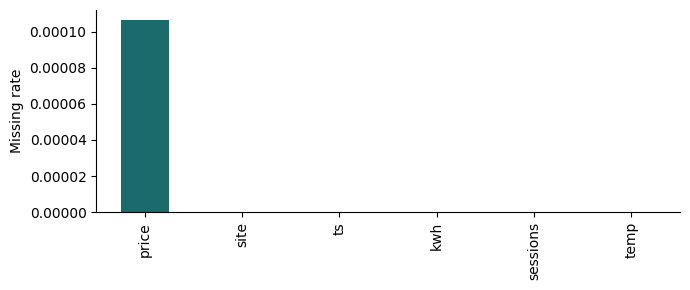

In [ ]:
miss = eda.isna().mean().sort_values(ascending=False).rename('missing_rate').to_frame()
miss['decision'] = np.select([miss.missing_rate == 0, miss.missing_rate < 0.05, miss.missing_rate < 0.4],
                             ['keep', 'interpolate/impute median', 'drop or keep flag'], 'drop column')
miss.round(4).to_csv('report/table_missing.csv'); print(miss.head(15))
# missingness of the target by time and by unit
tcol, gcol = 'ts', 'site'
by_time = eda.groupby(pd.to_datetime(eda[tcol], errors='coerce').dt.to_period('M') if not np.issubdtype(eda[tcol].dtype, np.number) else eda[tcol])['kwh'].apply(lambda s: s.isna().mean())
by_unit = eda.groupby(gcol)['kwh'].apply(lambda s: s.isna().mean()).sort_values(ascending=False)
print('target missing by period (top):', by_time.sort_values(ascending=False).head(5).round(3).to_dict())
print('target missing by unit (top):', by_unit.head(5).round(3).to_dict())
# co-missingness matrix: do columns go missing together
co = eda.isna().astype(int); co = co.loc[:, co.sum() > 0]
if co.shape[1] > 1: print(co.corr().round(2))
fig, ax = plt.subplots(figsize=(7, 3))
miss.missing_rate.head(12).plot.bar(ax=ax, color='#1B6B6D'); ax.set_ylabel('Missing rate'); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_missing.png', dpi=300)

### 1.4. EDA phần 3: chọn cột và thống kê theo nhóm, theo thời gian

**Chọn cột** theo ba tiêu chí: (1) có ý nghĩa vật lý hoặc nghiệp vụ với mục tiêu; (2) có sẵn tại thời điểm dự báo (không phải giá trị tương lai); (3) không trùng lặp với cột khác (tương quan trên 0,95 thì giữ một). Bảng `table_columns.csv` ghi cột nào giữ, cột nào bỏ và vì sao; bảng này là một phần của mục Data trong bài.

**Thống kê**: trung bình, trung vị, phân vị 5 và 95 của mục tiêu theo nhóm và theo thời kỳ; đây là bảng đầu tiên trả lời RQ1 trước khi làm SQL.

In [3]:
# ============================================================
# 1.4 EDA PART 3
# COLUMN SELECTION + GROUP/TIME STATISTICS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

REPORT_DIR = Path("report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Dùng dataset đã xử lý 6 timestamp DST
eda = eda_clean.copy()

# ============================================================
# 1. CORRELATION MATRIX
# ============================================================

num_cols = [
    c for c in
    ["kwh", "sessions", "temp", "price"]
    if c in eda.columns
]

corr = eda[num_cols].corr()

print("===== CORRELATION MATRIX =====")
print(corr.round(3))

corr.round(3).to_csv(
    REPORT_DIR / "table_corr.csv"
)


# ============================================================
# 2. COLUMN SELECTION TABLE
# ============================================================

columns_table = [
    {
        "column": "kwh",
        "role": "Target",
        "decision": "Keep",
        "reason": "Biến mục tiêu cần dự báo."
    },
    {
        "column": "ts",
        "role": "Time key",
        "decision": "Keep",
        "reason": "Dùng để tạo đặc trưng giờ, ngày, tháng và lag."
    },
    {
        "column": "site",
        "role": "Unit key",
        "decision": "Keep",
        "reason": "Phân biệt Caltech và JPL."
    },
    {
        "column": "temp",
        "role": "External predictor",
        "decision": "Keep",
        "reason": (
            f"Có ý nghĩa vật lý; correlation với kWh = "
            f"{corr.loc['temp','kwh']:.3f}. "
            "Có thể có quan hệ phi tuyến."
        )
    },
    {
        "column": "price",
        "role": "External predictor",
        "decision": "Keep",
        "reason": (
            f"Biến giá điện có ý nghĩa nghiệp vụ; correlation với kWh = "
            f"{corr.loc['price','kwh']:.3f}. "
            "Không loại chỉ vì tương quan tuyến tính thấp."
        )
    },
    {
        "column": "sessions",
        "role": "Operational predictor",
        "decision": "Review for leakage",
        "reason": (
            f"Correlation với kWh rất cao = "
            f"{corr.loc['sessions','kwh']:.3f}. "
            "Chỉ dùng nếu số session tại thời điểm dự báo thực sự có sẵn; "
            "nếu không, cần dùng lag của sessions thay vì giá trị cùng giờ."
        )
    }
]

columns_df = pd.DataFrame(columns_table)

print("\n===== COLUMN SELECTION =====")
display(columns_df)

columns_df.to_csv(
    REPORT_DIR / "table_columns.csv",
    index=False
)


# ============================================================
# 3. TARGET STATISTICS BY SITE
# ============================================================

def target_stats(s):
    return pd.Series({
        "mean": s.mean(),
        "median": s.median(),
        "p05": s.quantile(0.05),
        "p95": s.quantile(0.95),
        "n": s.count()
    })


by_site = (
    eda
    .groupby("site")["kwh"]
    .apply(target_stats)
    .unstack()
    .sort_values("mean", ascending=False)
)

print("\n===== KWH STATISTICS BY SITE =====")
print(by_site.round(3))

by_site.round(3).to_csv(
    REPORT_DIR / "table_target_by_unit.csv"
)


# ============================================================
# 4. TARGET STATISTICS BY MONTH
# ============================================================

eda["month"] = pd.to_datetime(
    eda["ts"]
).dt.month

by_month = (
    eda
    .groupby("month")["kwh"]
    .apply(target_stats)
    .unstack()
)

print("\n===== KWH STATISTICS BY MONTH =====")
print(by_month.round(3))

by_month.round(3).to_csv(
    REPORT_DIR / "table_target_by_period.csv"
)


# ============================================================
# 5. HIGH CORRELATION CHECK
# ============================================================

print("\n===== HIGH CORRELATION PAIRS > 0.95 =====")

high_corr = []

for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):

        c1 = num_cols[i]
        c2 = num_cols[j]

        r = corr.loc[c1, c2]

        if abs(r) > 0.95:

            high_corr.append({
                "column_1": c1,
                "column_2": c2,
                "correlation": round(r, 3)
            })

high_corr_df = pd.DataFrame(high_corr)

if len(high_corr_df) > 0:
    display(high_corr_df)
else:
    print("Không có cặp predictor nào có |correlation| > 0.95.")

high_corr_df.to_csv(
    REPORT_DIR / "table_high_corr.csv",
    index=False
)

print("\nEDA PART 3 DONE")

NameError: name 'eda_clean' is not defined

## Bước 3: phân tích bằng SQL, trả lời RQ1 và tạo đặc trưng

**Làm gì**: đưa parquet vào DuckDB; Q1 và Q2 tổng hợp trả lời RQ1 (GROUP BY, window, CTE); Q3 tạo đặc trưng trễ, trung bình trượt và mục tiêu tương lai bằng LAG, LEAD, AVG OVER; Q4 kiểm tra chất lượng. Lưu toàn bộ vào `sql/queries.sql`; mỗi truy vấn SELECT được lưu thành `report/table_q*.csv`.

**Kiểm tra**: chọn một đơn vị và 10 dòng, tính tay trung bình trượt rồi so với SQL; không đặc trưng nào dùng giá trị sau thời điểm dự báo.

In [ ]:
from pathlib import Path

p1 = Path("data/processed/acn_final.parquet")
p2 = Path("data/processed/acn.parquet")

print("acn_final.parquet:", p1.exists())
print("acn.parquet:", p2.exists())

acn_final.parquet: True
acn.parquet: True


In [ ]:
import duckdb

# Mở DuckDB trong RAM để tránh lỗi file ady.duckdb bị khóa
con = duckdb.connect()

# Đọc parquet cuối cùng vào DuckDB
con.execute("""
CREATE OR REPLACE TABLE ev AS
SELECT *
FROM 'data/processed/acn_final.parquet'
""")

# Kiểm tra số dòng và cột
check = con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(*) FILTER (WHERE price IS NULL) AS missing_price,
    COUNT(*) FILTER (WHERE kwh IS NULL) AS missing_kwh
FROM ev
""").df()

print(check)

# Xem thử 5 dòng đầu
print(
    con.execute("""
    SELECT *
    FROM ev
    LIMIT 5
    """).df()
)

    rows  missing_price  missing_kwh
0  56223              0            0
      site                  ts        kwh  sessions   temp     price
0  caltech 2018-04-25 04:00:00   2.644000       1.0  12.20  22.32440
1  caltech 2018-04-25 05:00:00   2.644000       1.0  11.95  40.76139
2  caltech 2018-04-25 06:00:00   3.956326       3.0  12.10  46.00595
3  caltech 2018-04-25 07:00:00   7.718726       7.0  13.60  31.03577
4  caltech 2018-04-25 08:00:00  16.894355      22.0  17.20  23.88378


In [ ]:
# ============================================================
# STEP 3 - Q1
# WORKPLACE CHARGING PROFILE BY SITE, WEEKDAY AND HOUR
# ============================================================

from pathlib import Path

Path("report").mkdir(parents=True, exist_ok=True)

q1 = con.execute("""
SELECT
    site,
    dayofweek(ts) AS dow,
    hour(ts) AS hr,
    AVG(kwh) AS avg_kwh,
    MEDIAN(kwh) AS median_kwh,
    COUNT(*) AS n
FROM ev
GROUP BY
    site,
    dayofweek(ts),
    hour(ts)
ORDER BY
    site,
    dow,
    hr
""").df()

# Lưu kết quả
q1.to_csv(
    "report/table_q1.csv",
    index=False
)

print("Shape:", q1.shape)

print("\n20 dòng đầu:")
print(q1.head(20))

print("\nĐã lưu: report/table_q1.csv")

Shape: (336, 6)

20 dòng đầu:
       site  dow  hr    avg_kwh  median_kwh    n
0   caltech    0   0   2.559111    0.920790  177
1   caltech    0   1   2.356396    0.920790  177
2   caltech    0   2   2.323106    0.920790  177
3   caltech    0   3   2.326313    0.907533  177
4   caltech    0   4   2.186537    0.723034  177
5   caltech    0   5   2.213779    0.723034  177
6   caltech    0   6   2.681017    1.491238  177
7   caltech    0   7   3.895934    1.904829  177
8   caltech    0   8   4.985549    2.419701  177
9   caltech    0   9   6.500531    3.562316  177
10  caltech    0  10   8.107441    4.832125  177
11  caltech    0  11   9.216207    5.351323  177
12  caltech    0  12   9.992410    6.536286  177
13  caltech    0  13  10.369965    6.451537  177
14  caltech    0  14  10.402852    6.597347  177
15  caltech    0  15   9.834810    6.721919  177
16  caltech    0  16  10.330404    6.721919  177
17  caltech    0  17   9.865875    5.232400  177
18  caltech    0  18   9.046429    5.40

In [ ]:
from pathlib import Path

file_q1 = Path("report/table_q1.csv")

print("Exists:", file_q1.exists())
print("Full path:", file_q1.resolve())

Exists: True
Full path: C:\Users\ASUS\Downloads\report\table_q1.csv


In [ ]:
# SQL statements run one by one in DuckDB; each SELECT prints its first 20 rows and is saved to report/table_q{k}.csv
import duckdb
if 'con' not in globals(): con = duckdb.connect('data/processed/ady.duckdb')   # reuse the connection opened in Step 1
SQL = r"""
-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE ev AS SELECT * FROM 'data/processed/acn.parquet';
-- Q1: workplace charging profile by site, weekday and hour; the 2020 drop
SELECT site, dayofweek(ts) AS dow, hour(ts) AS hr, AVG(kwh) AS kwh FROM ev GROUP BY 1, 2, 3 ORDER BY 1, 2, 3;
SELECT site, date_trunc('month', ts) AS ym, SUM(kwh) AS kwh FROM ev GROUP BY 1, 2 ORDER BY 1, 2;
-- Q2: price response: charging by price bin in the afternoon
SELECT FLOOR(price / 20) * 20 AS price_bin, AVG(kwh) AS kwh FROM ev WHERE hour(ts) BETWEEN 13 AND 18 GROUP BY 1 ORDER BY 1;
-- Q3: features and targets 1 h and 24 h ahead
CREATE OR REPLACE TABLE feat AS
SELECT site, ts, kwh, sessions, temp, price, hour(ts) AS hr, dayofweek(ts) AS dow, month(ts) AS mon,
       LAG(kwh, 1) OVER w AS k_lag1, LAG(kwh, 24) OVER w AS k_lag24, LAG(kwh, 168) OVER w AS k_lag168, AVG(kwh) OVER (w ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS k_ma24,
       LEAD(kwh, 1) OVER w AS y_1h, LEAD(kwh, 24) OVER w AS y_24h
FROM ev WINDOW w AS (PARTITION BY site ORDER BY ts);
SELECT COUNT(*) AS n, COUNT(y_24h) AS n24 FROM feat;
"""
k = 0
SQL_NO_COMMENTS = '\n'.join(l for l in SQL.splitlines() if not l.strip().startswith('--'))   # drop comment lines first (they may contain semicolons)
for stmt in SQL_NO_COMMENTS.split(';'):
    stmt = stmt.strip()
    if not stmt: continue
    res = con.execute(stmt)
    if stmt.upper().startswith(('SELECT', 'WITH')):
        k += 1; out = res.df(); out.to_csv(f'report/table_q{k}.csv', index=False); print(f'--- Q{k} ---'); print(out.head(20))
open('sql/queries.sql', 'w').write(SQL)

--- Q1 ---
       site  dow  hr        kwh
0   caltech    0   0   2.559111
1   caltech    0   1   2.356396
2   caltech    0   2   2.323106
3   caltech    0   3   2.326313
4   caltech    0   4   2.186537
5   caltech    0   5   2.213779
6   caltech    0   6   2.681017
7   caltech    0   7   3.895934
8   caltech    0   8   4.985549
9   caltech    0   9   6.500531
10  caltech    0  10   8.107441
11  caltech    0  11   9.216207
12  caltech    0  12   9.992410
13  caltech    0  13  10.369965
14  caltech    0  14  10.402852
15  caltech    0  15   9.834810
16  caltech    0  16  10.330404
17  caltech    0  17   9.865875
18  caltech    0  18   9.046429
19  caltech    0  19   8.543478
--- Q2 ---
       site         ym           kwh
0   caltech 2018-04-01   2353.103491
1   caltech 2018-05-01  15695.532401
2   caltech 2018-06-01  16875.660368
3   caltech 2018-07-01  18979.559902
4   caltech 2018-08-01  20652.002497
5   caltech 2018-09-01  20657.592591
6   caltech 2018-10-01  22582.002222
7   caltec

1096

In [ ]:
con.execute("""
CREATE OR REPLACE TABLE ev AS
SELECT *
FROM 'data/processed/acn_final.parquet'
""")

print(
    con.execute("""
        SELECT
            COUNT(*) AS n,
            COUNT(*) FILTER (WHERE price IS NULL) AS missing_price,
            COUNT(*) FILTER (WHERE kwh IS NULL) AS missing_kwh
        FROM ev
    """).df()
)

       n  missing_price  missing_kwh
0  56223              0            0


### 3.2. Tiếp nối SQL: bảng trả lời RQ1 bằng pandas và kiểm định

**Làm gì**: từ kết quả Q1, Q2 dựng bảng có số thứ tự đưa thẳng vào bài; kiểm định khác biệt giữa nhóm (Kruskal-Wallis, không cần giả định chuẩn) và tương quan Spearman giữa mục tiêu và các biến ngoại sinh kèm p-value.

**Đọc thế nào**: p < 0,05 nghĩa là khác biệt giữa nhóm khó do ngẫu nhiên; hệ số Spearman cho chiều và độ mạnh quan hệ đơn điệu; kết luận RQ1 phải là một câu có số, ví dụ "mùa đông cao gấp 1,9 lần mùa hè, p < 0,001".

In [ ]:
Code đã thay đổi

In [ ]:
# ============================================================
# 3.2. RQ1 TABLES + STATISTICAL TESTS
# ============================================================

import duckdb
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import kruskal, spearmanr

# ============================================================
# 0. CREATE OUTPUT FOLDER
# ============================================================

REPORT_DIR = Path("report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. CONNECT DUCKDB
# ============================================================

# Dùng DuckDB trong RAM để tránh lỗi file database bị khóa
con = duckdb.connect()


# ============================================================
# 2. LOAD FINAL DATASET
# ============================================================

con.execute("""
CREATE OR REPLACE TABLE ev AS
SELECT *
FROM 'data/processed/acn_final.parquet'
""")


check = con.execute("""
SELECT
    COUNT(*) AS n,
    COUNT(*) FILTER (WHERE kwh IS NULL) AS missing_kwh,
    COUNT(*) FILTER (WHERE price IS NULL) AS missing_price
FROM ev
""").df()

print("===== INPUT DATA CHECK =====")
print(check)


# ============================================================
# 3. CREATE FEATURE TABLE
# ============================================================

con.execute("""
CREATE OR REPLACE TABLE feat AS

SELECT
    site,
    ts,
    kwh,
    sessions,
    temp,
    price,

    hour(ts) AS hr,
    dayofweek(ts) AS dow,
    month(ts) AS mon,

    LAG(kwh, 1)
        OVER w AS k_lag1,

    LAG(kwh, 24)
        OVER w AS k_lag24,

    LAG(kwh, 168)
        OVER w AS k_lag168,

    AVG(kwh) OVER (
        PARTITION BY site
        ORDER BY ts
        ROWS BETWEEN 23 PRECEDING AND CURRENT ROW
    ) AS k_ma24,

    LEAD(kwh, 1)
        OVER w AS y_1h,

    LEAD(kwh, 24)
        OVER w AS y_24h

FROM ev

WINDOW w AS (
    PARTITION BY site
    ORDER BY ts
)
""")


# ============================================================
# 4. LOAD FEATURE TABLE TO PANDAS
# ============================================================

q1 = con.execute("""
SELECT *
FROM feat
ORDER BY site, ts
""").df()


q1["ts"] = pd.to_datetime(
    q1["ts"],
    errors="coerce"
)

# Tháng 1 -> 12
q1["period"] = q1["ts"].dt.month


print("\n===== FEATURE DATA =====")
print("Shape:", q1.shape)
print(q1.head())


# ============================================================
# 5. RQ1A
# TARGET KWH BY MONTH
# ============================================================

print("\n============================================================")
print("RQ1A - KWH BY MONTH")
print("============================================================")


def target_stats(series):

    return pd.Series({
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "p05": series.quantile(0.05),
        "p95": series.quantile(0.95),
        "count": series.count()
    })


rq1a = (
    q1
    .groupby("period")["kwh"]
    .apply(target_stats)
    .unstack()
)

rq1a = rq1a.round(3)

print(rq1a)


rq1a.to_csv(
    REPORT_DIR / "table_rq1a_period.csv"
)


# ============================================================
# 6. KRUSKAL-WALLIS TEST
# ============================================================

groups = [
    group["kwh"].dropna().values
    for _, group in q1.groupby("period")
    if group["kwh"].notna().sum() > 30
]


if len(groups) > 1:

    kw_stat, kw_p = kruskal(*groups)

    print("\n===== KRUSKAL-WALLIS TEST =====")

    print(
        f"H statistic = {kw_stat:.3f}"
    )

    print(
        f"p-value = {kw_p:.6e}"
    )

    if kw_p < 0.05:

        print(
            "Kết luận: Có sự khác biệt có ý nghĩa thống kê "
            "về phân phối kWh giữa các tháng."
        )

    else:

        print(
            "Kết luận: Chưa có bằng chứng về sự khác biệt "
            "có ý nghĩa thống kê giữa các tháng."
        )


    kruskal_table = pd.DataFrame([
        {
            "test": "Kruskal-Wallis",
            "statistic": kw_stat,
            "p_value": kw_p,
            "significant_0.05": kw_p < 0.05
        }
    ])

    kruskal_table.to_csv(
        REPORT_DIR /
        "table_rq1a_kruskal.csv",
        index=False
    )

else:

    kw_stat = np.nan
    kw_p = np.nan

    print(
        "Không đủ nhóm để chạy Kruskal-Wallis."
    )


# ============================================================
# 7. RQ1B
# SPEARMAN CORRELATION
# ============================================================

print("\n============================================================")
print("RQ1B - SPEARMAN CORRELATION")
print("============================================================")

# Chỉ chọn biến phù hợp để giải thích RQ1.
# KHÔNG đưa y_1h/y_24h hoặc lag của target vào bảng ngoại sinh.

ext_vars = [
    c for c in
    [
        "sessions",
        "temp",
        "price",
        "hr",
        "dow"
    ]
    if c in q1.columns
]


spearman_rows = []


for c in ext_vars:

    x = q1[c]
    y = q1["kwh"]

    valid = (
        x.notna()
        &
        y.notna()
    )

    r, p_value = spearmanr(
        x[valid],
        y[valid]
    )


    if abs(r) >= 0.7:
        strength = "strong"

    elif abs(r) >= 0.4:
        strength = "moderate"

    elif abs(r) >= 0.2:
        strength = "weak"

    else:
        strength = "very weak"


    if r > 0:
        direction = "positive"

    elif r < 0:
        direction = "negative"

    else:
        direction = "none"


    spearman_rows.append({
        "variable": c,
        "spearman_r": round(r, 3),
        "p_value": p_value,
        "direction": direction,
        "strength": strength,
        "significant_0.05": p_value < 0.05
    })


rq1b = pd.DataFrame(
    spearman_rows
)

rq1b = (
    rq1b
    .sort_values(
        "spearman_r",
        key=abs,
        ascending=False
    )
    .reset_index(drop=True)
)


print(rq1b)


rq1b.to_csv(
    REPORT_DIR /
    "table_rq1b_corr.csv",
    index=False
)


# ============================================================
# 8. RQ1C
# TARGET KWH BY SITE
# ============================================================

print("\n============================================================")
print("RQ1C - KWH BY SITE")
print("============================================================")


rq1c = (
    q1
    .groupby("site")["kwh"]
    .apply(target_stats)
    .unstack()
    .sort_values(
        "mean",
        ascending=False
    )
)

rq1c = rq1c.round(3)

print(rq1c)


rq1c.to_csv(
    REPORT_DIR /
    "table_rq1c_units.csv"
)


# ============================================================
# 9. RQ1 CONCLUSION
# ============================================================

highest_month = int(
    rq1a["mean"].idxmax()
)

lowest_month = int(
    rq1a["mean"].idxmin()
)

highest_mean = float(
    rq1a.loc[
        highest_month,
        "mean"
    ]
)

lowest_mean = float(
    rq1a.loc[
        lowest_month,
        "mean"
    ]
)

ratio = (
    highest_mean /
    lowest_mean
    if lowest_mean != 0
    else np.nan
)


print("\n============================================================")
print("RQ1 CONCLUSION")
print("============================================================")

print(
    f"Tháng có tải trung bình cao nhất: "
    f"tháng {highest_month} "
    f"({highest_mean:.3f} kWh)."
)

print(
    f"Tháng có tải trung bình thấp nhất: "
    f"tháng {lowest_month} "
    f"({lowest_mean:.3f} kWh)."
)

print(
    f"Tỷ lệ cao nhất / thấp nhất: "
    f"{ratio:.2f} lần."
)


if pd.notna(kw_p):

    if kw_p < 0.001:

        p_text = "p < 0.001"

    else:

        p_text = f"p = {kw_p:.4f}"


    conclusion = (
        f"Tải sạc EV thay đổi có ý nghĩa thống kê theo tháng "
        f"(Kruskal-Wallis H = {kw_stat:.2f}, {p_text}). "
        f"Tháng {highest_month} có tải trung bình cao nhất "
        f"({highest_mean:.2f} kWh), cao khoảng "
        f"{ratio:.2f} lần so với tháng {lowest_month} "
        f"({lowest_mean:.2f} kWh)."
    )

else:

    conclusion = (
        "Không đủ dữ liệu để thực hiện kiểm định "
        "Kruskal-Wallis."
    )


print("\nCâu dùng cho báo cáo:")
print(conclusion)


# ============================================================
# 10. SAVE CONCLUSION
# ============================================================

with open(
    REPORT_DIR /
    "rq1_conclusion.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(conclusion)


# ============================================================
# 11. SUMMARY OF OUTPUT FILES
# ============================================================

print("\n============================================================")
print("3.2 DONE")
print("============================================================")

print("Đã tạo:")

print(
    "report/table_rq1a_period.csv"
)

print(
    "report/table_rq1a_kruskal.csv"
)

print(
    "report/table_rq1b_corr.csv"
)

print(
    "report/table_rq1c_units.csv"
)

print(
    "report/rq1_conclusion.txt"
)

===== INPUT DATA CHECK =====
       n  missing_kwh  missing_price
0  56223            0              0

===== FEATURE DATA =====
Shape: (56223, 16)
      site                  ts        kwh  sessions   temp     price  hr  dow  mon    k_lag1  k_lag24  k_lag168    k_ma24       y_1h      y_24h  period
0  caltech 2018-04-25 04:00:00   2.644000       1.0  12.20  22.32440   4    3    4       NaN      NaN       NaN  2.644000   2.644000   4.500776       4
1  caltech 2018-04-25 05:00:00   2.644000       1.0  11.95  40.76139   5    3    4  2.644000      NaN       NaN  2.644000   3.956326   4.408049       4
2  caltech 2018-04-25 06:00:00   3.956326       3.0  12.10  46.00595   6    3    4  2.644000      NaN       NaN  3.081442   7.718726   3.671923       4
3  caltech 2018-04-25 07:00:00   7.718726       7.0  13.60  31.03577   7    3    4  3.956326      NaN       NaN  4.240763  16.894355   5.586432       4
4  caltech 2018-04-25 08:00:00  16.894355      22.0  17.20  23.88378   8    3    4  7.718726

In [ ]:
from scipy.stats import kruskal, spearmanr
q1 = con.execute("SELECT * FROM feat").df()          # feature table created in Q3
if np.issubdtype(q1['ts'].dtype, np.number): q1['period'] = q1['ts']            # numeric time key (year, cycle)
else: q1['period'] = pd.to_datetime(q1['ts'], errors='coerce').dt.month             # datetime key: use month as period
# Table RQ1a: target by period
rq1a = q1.groupby('period')['kwh'].agg(['mean', 'median', 'std', 'count']).round(3)
rq1a.to_csv('report/table_rq1a_period.csv'); print(rq1a)
groups = [s.values for _, s in q1.groupby('period')['kwh'] if len(s) > 30]
if len(groups) > 1: print('Kruskal-Wallis across periods:', kruskal(*groups))
# Table RQ1b: Spearman correlation of the target with exogenous variables
ext = [c for c in q1.select_dtypes('number').columns if c not in ('kwh', 'y_24h') and not c.startswith('kwh')]
rows = []
for c in ext[:15]:
    r, pv = spearmanr(q1[c], q1['kwh'], nan_policy='omit'); rows.append([c, round(r, 3), pv])
rq1b = pd.DataFrame(rows, columns=['variable', 'spearman_r', 'p_value']).sort_values('spearman_r', key=abs, ascending=False)
rq1b.to_csv('report/table_rq1b_corr.csv', index=False); print(rq1b)
# Table RQ1c: target by unit, top and bottom 5
rq1c = q1.groupby('site')['kwh'].agg(['mean', 'count']).sort_values('mean', ascending=False)
pd.concat([rq1c.head(5), rq1c.tail(5)]).round(3).to_csv('report/table_rq1c_units.csv')
print('RQ1 CONCLUSION (fill with real numbers): highest period', rq1a['mean'].idxmax(), 'is', round(rq1a['mean'].max() / max(rq1a['mean'].min(), 1e-9), 2), 'times the lowest period')

          mean  median     std  count
period                               
1       15.396   3.460  25.660   4464
2       16.022   3.688  26.667   4080
3       12.731   3.183  22.595   4458
4       11.161   2.296  20.600   4460
5       12.501   3.862  20.366   5208
6       13.296   4.123  20.363   5040
7       12.770   3.261  20.900   5208
8       13.594   2.161  22.152   5208
9       13.603   1.049  22.922   4849
10      16.491   1.836  26.587   4464
11      13.168   1.603  23.921   4320
12      12.766   2.420  23.818   4464
Kruskal-Wallis across periods: KruskalResult(statistic=np.float64(337.1374226281589), pvalue=np.float64(1.2730865648476552e-65))
    variable  spearman_r       p_value
0   sessions       0.974  0.000000e+00
6     k_lag1       0.929  0.000000e+00
10      y_1h       0.929  0.000000e+00
8   k_lag168       0.804  0.000000e+00
7    k_lag24       0.735  0.000000e+00
9     k_ma24       0.629  0.000000e+00
1       temp       0.221  0.000000e+00
3         hr       0.171  0

## Bước 5 (phần A): bộ hình đa dạng trả lời RQ1

Mỗi hình gắn với một ý của RQ1 và có caption là kết luận. Bộ hình: (1) phân phối mục tiêu, histogram và boxplot; (2) chuỗi theo thời gian của vài đơn vị; (3) heatmap thời kỳ x đơn vị; (4) boxplot mục tiêu theo thời kỳ; (5) scatter mục tiêu với biến ngoại sinh mạnh nhất; (6) heatmap tương quan; (7) so sánh nhóm bằng cột có số. Quy tắc: chữ tiếng Anh, bỏ viền trên và phải, số in đậm trên cột, 300 dpi, tên file `fig_rq1_*.png`.

In [ ]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# SETUP
# =========================================================
REPORT_DIR = Path("report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = Path("data/processed/acn.parquet")

# =========================================================
# LOAD DATA
# =========================================================
if "q1" in globals():
    d = q1.copy()
    print("Using existing q1 from notebook.")
else:
    if not DATA_FILE.exists():
        raise FileNotFoundError(
            f"Không tìm thấy file: {DATA_FILE}\n"
            "Hãy kiểm tra lại bước 2 hoặc đường dẫn file."
        )
    d = pd.read_parquet(DATA_FILE)
    print(f"Loaded data from: {DATA_FILE}")

# =========================================================
# BASIC PREP
# =========================================================
d["ts"] = pd.to_datetime(d["ts"], errors="coerce")

# period = month for RQ1
d["period"] = d["ts"].dt.month

# make sure numeric columns are numeric
for c in ["kwh", "sessions", "temp", "price"]:
    if c in d.columns:
        d[c] = pd.to_numeric(d[c], errors="coerce")

# keep valid rows for plotting target
d = d.dropna(subset=["kwh", "ts"]).copy()

print("Shape:", d.shape)
print("Columns:", d.columns.tolist())
print(d.head())

Using existing q1 from notebook.
Shape: (56223, 16)
Columns: ['site', 'ts', 'kwh', 'sessions', 'temp', 'price', 'hr', 'dow', 'mon', 'k_lag1', 'k_lag24', 'k_lag168', 'k_ma24', 'y_1h', 'y_24h', 'period']
  site                  ts  kwh  sessions  temp     price  hr  dow  mon  k_lag1  k_lag24  k_lag168  k_ma24  y_1h  y_24h  period
0  jpl 2020-07-18 22:00:00  0.0       0.0  18.9  24.62000  22    6    7     0.0      0.0       0.0  1.2555   0.0    0.0       7
1  jpl 2020-07-18 23:00:00  0.0       0.0  18.9  22.74761  23    6    7     0.0      0.0       0.0  1.2555   0.0    0.0       7
2  jpl 2020-07-19 00:00:00  0.0       0.0  18.3  22.82027   0    0    7     0.0      0.0       0.0  1.2555   0.0    0.0       7
3  jpl 2020-07-19 01:00:00  0.0       0.0  17.8  22.72809   1    0    7     0.0      0.0       0.0  1.2555   0.0    0.0       7
4  jpl 2020-07-19 02:00:00  0.0       0.0  17.2  22.19778   2    0    7     0.0      0.0       0.0  1.2555   0.0    0.0       7


Using data:
C:\Users\ASUS\Downloads\data\processed\acn_final.parquet

DATA VALIDATION
Rows:
56223

Date range:
2018-04-25 04:00:00 -> 2021-09-14 07:00:00

Sites:
site
caltech    29702
jpl        26521
Name: count, dtype: int64

Missing values:
kwh         0
sessions    0
temp        0
price       0
dtype: int64


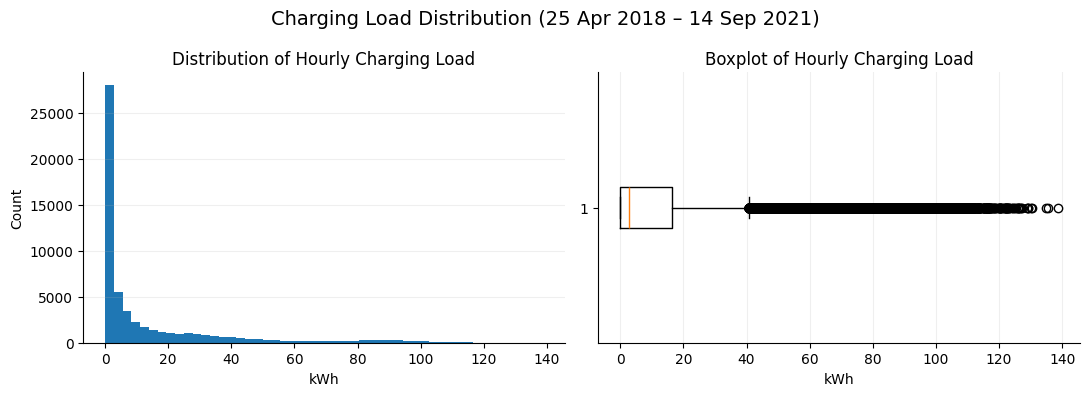

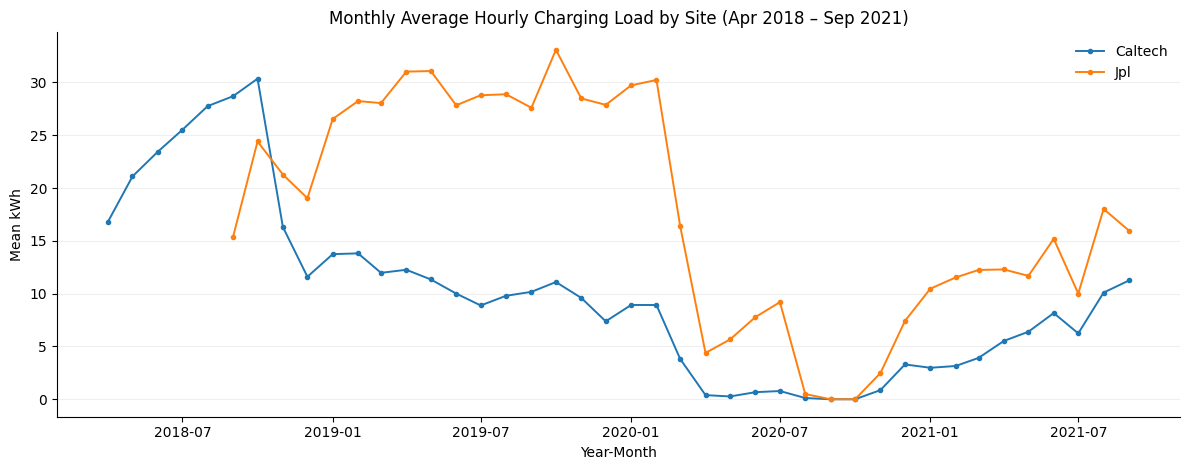

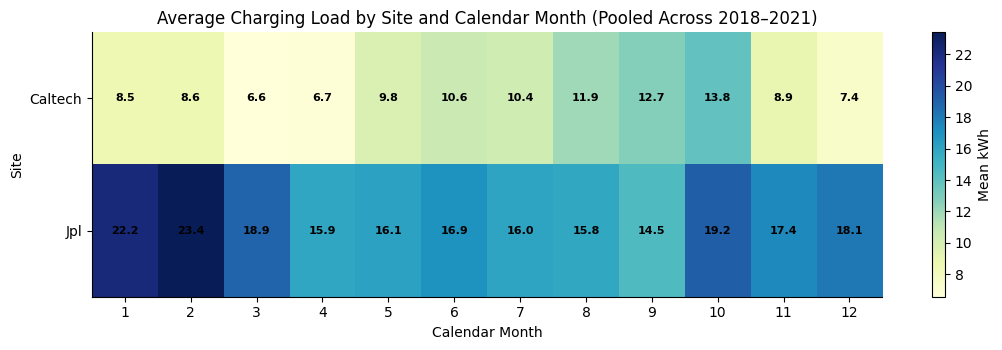

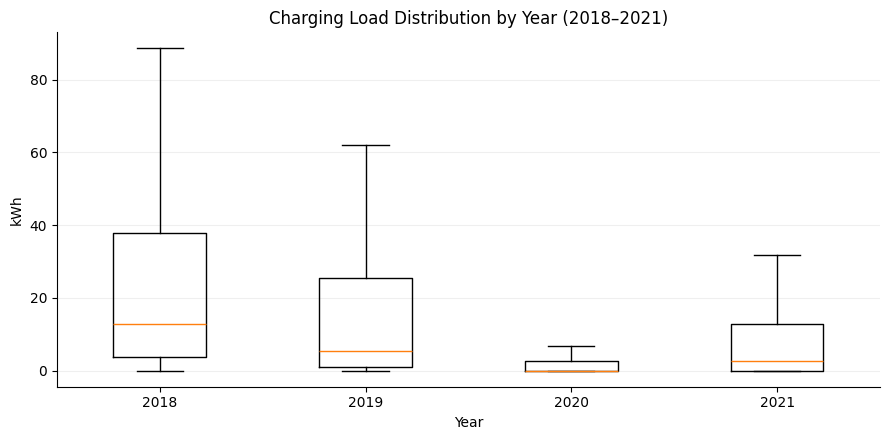

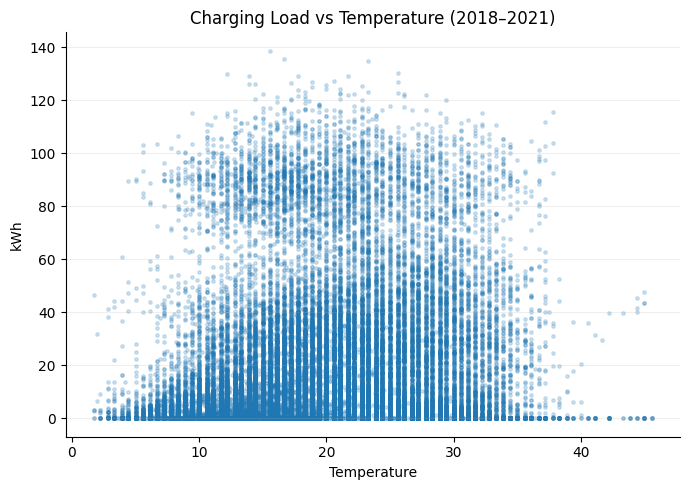

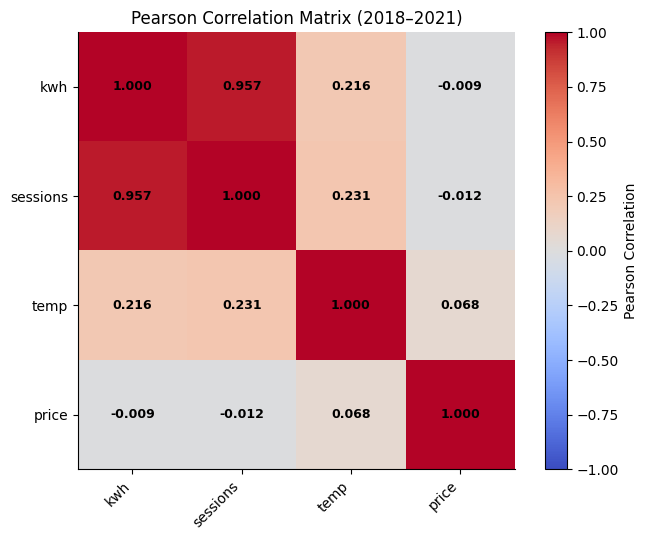

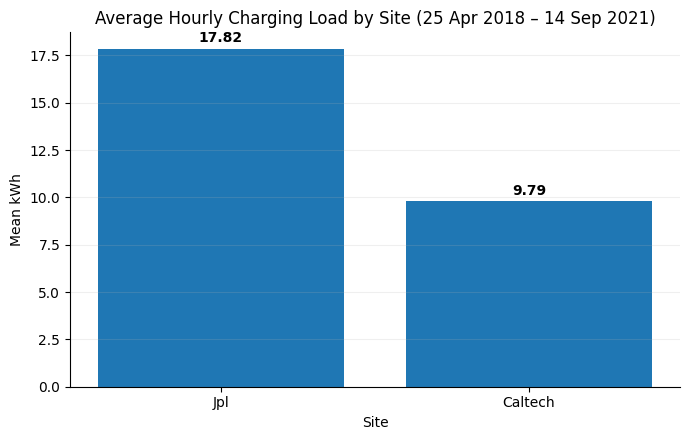


NUMERICAL VALIDATION

[1] Overall kWh statistics:
count    56223.000
mean        13.580
std         23.065
min          0.000
25%          0.000
50%          2.829
75%         16.268
max        138.727
Name: kwh, dtype: float64
Skewness: 2.295

[2] Calendar month statistics (pooled across available years):
       mean_kwh  median_kwh  count
month                             
1        15.396       3.460   4464
2        16.022       3.688   4080
3        12.731       3.183   4458
4        11.161       2.296   4460
5        12.501       3.862   5208
6        13.296       4.123   5040
7        12.770       3.261   5208
8        13.594       2.161   5208
9        13.603       1.049   4849
10       16.491       1.836   4464
11       13.168       1.603   4320
12       12.766       2.420   4464

Highest mean calendar month: 10 = 16.491 kWh
Lowest mean calendar month: 4 = 11.161 kWh
Highest / lowest ratio: 1.48

[3] Year statistics:
      mean_kwh  median_kwh  count
year                       

In [ ]:
# ============================================================
# STEP 5A - FINAL RQ1 FIGURES
# VS CODE / JUPYTER
# 7 UNIQUE FIGURES - REAL DATA ONLY
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. PATHS
# ============================================================

DATA_FILE = Path("data/processed/acn_final.parquet")
REPORT_DIR = Path("report")

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Không tìm thấy file:\n{DATA_FILE.resolve()}"
    )

print("Using data:")
print(DATA_FILE.resolve())


# ============================================================
# 1. LOAD FINAL DATA
# ============================================================

d = pd.read_parquet(
    DATA_FILE
).copy()


required_cols = [
    "site",
    "ts",
    "kwh",
    "sessions",
    "temp",
    "price"
]

missing_cols = [
    c for c in required_cols
    if c not in d.columns
]

if missing_cols:
    raise ValueError(
        f"Dataset thiếu cột: {missing_cols}"
    )


# ============================================================
# 2. PREPARE DATA
# ============================================================

d["ts"] = pd.to_datetime(
    d["ts"],
    errors="coerce"
)

for c in [
    "kwh",
    "sessions",
    "temp",
    "price"
]:
    d[c] = pd.to_numeric(
        d[c],
        errors="coerce"
    )


# Remove rows missing essential values
d = d.dropna(
    subset=[
        "site",
        "ts",
        "kwh"
    ]
).copy()


# Standardize site name
d["site"] = (
    d["site"]
    .astype(str)
    .str.strip()
    .str.lower()
)


# ============================================================
# TIME VARIABLES
# ============================================================

# Year: 2018, 2019, 2020, 2021
d["year"] = (
    d["ts"]
    .dt
    .year
)

# Calendar month: 1 -> 12
d["month"] = (
    d["ts"]
    .dt
    .month
)

# Real chronological month
# 2018-04 -> ... -> 2021-09
d["year_month"] = (
    d["ts"]
    .dt
    .to_period("M")
    .dt
    .to_timestamp()
)

# Hour of day
d["hour"] = (
    d["ts"]
    .dt
    .hour
)

# Monday=0 ... Sunday=6
d["dow"] = (
    d["ts"]
    .dt
    .dayofweek
)


# ============================================================
# 3. DATA VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("Rows:")
print(len(d))

print("\nDate range:")
print(
    d["ts"].min(),
    "->",
    d["ts"].max()
)

print("\nSites:")
print(
    d["site"]
    .value_counts()
)

print("\nMissing values:")
print(
    d[
        [
            "kwh",
            "sessions",
            "temp",
            "price"
        ]
    ]
    .isna()
    .sum()
)


# ============================================================
# 4. COMMON STYLE
# ============================================================

def style_ax(ax, grid_axis="y"):

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    if grid_axis is not None:
        ax.grid(
            axis=grid_axis,
            alpha=0.20
        )


# ============================================================
# FIGURE 1
# OVERALL TARGET DISTRIBUTION
# ALL DATA: 2018-04-25 -> 2021-09-14
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)


# Histogram
axes[0].hist(
    d["kwh"].dropna(),
    bins=50
)

axes[0].set_title(
    "Distribution of Hourly Charging Load"
)

axes[0].set_xlabel(
    "kWh"
)

axes[0].set_ylabel(
    "Count"
)

style_ax(
    axes[0],
    grid_axis="y"
)


# Overall boxplot
axes[1].boxplot(
    d["kwh"].dropna(),
    vert=False,
    showfliers=True
)

axes[1].set_title(
    "Boxplot of Hourly Charging Load"
)

axes[1].set_xlabel(
    "kWh"
)

style_ax(
    axes[1],
    grid_axis="x"
)


fig.suptitle(
    "Charging Load Distribution "
    "(25 Apr 2018 – 14 Sep 2021)",
    fontsize=14
)

fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2
# MONTHLY AVERAGE HOURLY LOAD BY SITE
#
# Keeps full chronological time:
# 2018-04 -> ... -> 2021-09
#
# Mean is used instead of total so partial months
# are more comparable.
# ============================================================

monthly_site = (
    d.groupby(
        [
            "site",
            "year_month"
        ],
        as_index=False
    )
    .agg(
        mean_kwh=(
            "kwh",
            "mean"
        )
    )
    .sort_values(
        [
            "site",
            "year_month"
        ]
    )
)


fig, ax = plt.subplots(
    figsize=(12, 4.8)
)


for site in sorted(
    monthly_site[
        "site"
    ].unique()
):

    s = (
        monthly_site[
            monthly_site[
                "site"
            ] == site
        ]
        .sort_values(
            "year_month"
        )
    )

    ax.plot(
        s[
            "year_month"
        ],

        s[
            "mean_kwh"
        ],

        marker="o",
        markersize=3,
        linewidth=1.4,

        label=str(
            site
        ).capitalize()
    )


ax.set_title(
    "Monthly Average Hourly Charging Load by Site "
    "(Apr 2018 – Sep 2021)"
)

ax.set_xlabel(
    "Year-Month"
)

ax.set_ylabel(
    "Mean kWh"
)

ax.legend(
    frameon=False
)

style_ax(ax)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_timeseries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3
# SITE x CALENDAR MONTH HEATMAP
#
# IMPORTANT:
# This intentionally pools same calendar months across years.
# Example:
# Month 8 = Aug 2018 + Aug 2019 + Aug 2020 + Aug 2021
#
# This figure is for SEASONALITY, not yearly trend.
# ============================================================

hm = (
    d.pivot_table(
        index="site",
        columns="month",
        values="kwh",
        aggfunc="mean"
    )
    .sort_index()
)


fig, ax = plt.subplots(
    figsize=(11, 3.6)
)


im = ax.imshow(
    hm.values,
    aspect="auto",
    cmap="YlGnBu"
)


ax.set_title(
    "Average Charging Load by Site and Calendar Month "
    "(Pooled Across 2018–2021)"
)

ax.set_xlabel(
    "Calendar Month"
)

ax.set_ylabel(
    "Site"
)


ax.set_xticks(
    np.arange(
        len(
            hm.columns
        )
    )
)

ax.set_xticklabels(
    hm.columns
)


ax.set_yticks(
    np.arange(
        len(
            hm.index
        )
    )
)

ax.set_yticklabels(
    [
        str(site).capitalize()
        for site in hm.index
    ]
)


# values inside heatmap
for i in range(
    hm.shape[0]
):

    for j in range(
        hm.shape[1]
    ):

        value = (
            hm.iloc[
                i,
                j
            ]
        )

        if pd.notna(
            value
        ):

            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold"
            )


cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Mean kWh"
)

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4
# DISTRIBUTION BY YEAR
#
# Keeps years separate:
# 2018 vs 2019 vs 2020 vs 2021
#
# Note:
# 2018 is partial: starts 25 Apr
# 2021 is partial: ends 14 Sep
# ============================================================

years = sorted(
    d[
        "year"
    ].dropna().unique()
)


box_data_year = [
    d.loc[
        d[
            "year"
        ] == year,
        "kwh"
    ]
    .dropna()
    .values

    for year in years
]


fig, ax = plt.subplots(
    figsize=(9, 4.5)
)


ax.boxplot(
    box_data_year,
    tick_labels=years,
    showfliers=False
)


ax.set_title(
    "Charging Load Distribution by Year "
    "(2018–2021)"
)

ax.set_xlabel(
    "Year"
)

ax.set_ylabel(
    "kWh"
)


style_ax(ax)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_box_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 5
# TARGET vs STRONGEST TRUE EXTERNAL VARIABLE
#
# Compare:
# temp
# price
#
# sessions is intentionally excluded because
# same-hour sessions are strongly linked to charging activity.
# ============================================================

external_candidates = [
    "temp",
    "price"
]


external_rows = []


for variable in external_candidates:

    tmp = (
        d[
            [
                variable,
                "kwh"
            ]
        ]
        .dropna()
    )

    rho = (
        tmp[
            variable
        ]
        .corr(
            tmp[
                "kwh"
            ],
            method="spearman"
        )
    )

    external_rows.append(
        {
            "variable":
                variable,

            "rho":
                rho,

            "abs_rho":
                abs(
                    rho
                )
        }
    )


external_corr = (
    pd.DataFrame(
        external_rows
    )
    .sort_values(
        "abs_rho",
        ascending=False
    )
)


strongest_external = (
    external_corr
    .iloc[0][
        "variable"
    ]
)


strongest_rho = (
    external_corr
    .iloc[0][
        "rho"
    ]
)


scatter_data = (
    d[
        [
            strongest_external,
            "kwh"
        ]
    ]
    .dropna()
)


if strongest_external == "temp":

    x_label = (
        "Temperature"
    )

else:

    x_label = (
        "Electricity Price"
    )


fig, ax = plt.subplots(
    figsize=(7, 5)
)


ax.scatter(
    scatter_data[
        strongest_external
    ],

    scatter_data[
        "kwh"
    ],

    s=6,
    alpha=0.20
)


ax.set_title(
    f"Charging Load vs {x_label} "
    "(2018–2021)"
)

ax.set_xlabel(
    x_label
)

ax.set_ylabel(
    "kWh"
)


style_ax(ax)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6
# PEARSON CORRELATION MATRIX
# ============================================================

corr_cols = [
    "kwh",
    "sessions",
    "temp",
    "price"
]


corr = (
    d[
        corr_cols
    ]
    .corr(
        method="pearson"
    )
)


fig, ax = plt.subplots(
    figsize=(7, 5.5)
)


im = ax.imshow(
    corr.values,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)


ax.set_title(
    "Pearson Correlation Matrix "
    "(2018–2021)"
)


ax.set_xticks(
    np.arange(
        len(
            corr.columns
        )
    )
)


ax.set_xticklabels(
    corr.columns,
    rotation=45,
    ha="right"
)


ax.set_yticks(
    np.arange(
        len(
            corr.index
        )
    )
)


ax.set_yticklabels(
    corr.index
)


for i in range(
    corr.shape[0]
):

    for j in range(
        corr.shape[1]
    ):

        value = (
            corr.iloc[
                i,
                j
            ]
        )

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold"
        )


cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Pearson Correlation"
)


ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_corr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7
# SITE COMPARISON
# JPL vs CALTECH
# ============================================================

site_stats = (
    d.groupby(
        "site",
        as_index=False
    )
    .agg(
        mean_kwh=(
            "kwh",
            "mean"
        ),

        median_kwh=(
            "kwh",
            "median"
        ),

        count=(
            "kwh",
            "count"
        )
    )
    .sort_values(
        "mean_kwh",
        ascending=False
    )
)


fig, ax = plt.subplots(
    figsize=(7, 4.5)
)


bars = ax.bar(
    site_stats[
        "site"
    ]
    .str
    .capitalize(),

    site_stats[
        "mean_kwh"
    ]
)


# bold values above bars
for bar, value in zip(
    bars,
    site_stats[
        "mean_kwh"
    ]
):

    ax.text(
        bar.get_x()
        +
        bar.get_width()
        / 2,

        bar.get_height()
        +
        0.2,

        f"{value:.2f}",

        ha="center",
        va="bottom",

        fontsize=10,
        fontweight="bold"
    )


ax.set_title(
    "Average Hourly Charging Load by Site "
    "(25 Apr 2018 – 14 Sep 2021)"
)

ax.set_xlabel(
    "Site"
)

ax.set_ylabel(
    "Mean kWh"
)


style_ax(ax)


fig.tight_layout()


fig.savefig(
    REPORT_DIR /
    "fig_rq1_site_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. NUMERICAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("NUMERICAL VALIDATION")
print("=" * 70)


# ------------------------------------------------------------
# Overall kWh
# ------------------------------------------------------------

print(
    "\n[1] Overall kWh statistics:"
)

print(
    d[
        "kwh"
    ]
    .describe()
    .round(3)
)

print(
    "Skewness:",
    round(
        d[
            "kwh"
        ]
        .skew(),
        3
    )
)


# ------------------------------------------------------------
# Monthly pooled statistics
# ------------------------------------------------------------

month_stats = (
    d.groupby(
        "month"
    )
    .agg(
        mean_kwh=(
            "kwh",
            "mean"
        ),

        median_kwh=(
            "kwh",
            "median"
        ),

        count=(
            "kwh",
            "count"
        )
    )
)


print(
    "\n[2] Calendar month statistics "
    "(pooled across available years):"
)

print(
    month_stats.round(
        3
    )
)


highest_month = (
    month_stats[
        "mean_kwh"
    ]
    .idxmax()
)


lowest_month = (
    month_stats[
        "mean_kwh"
    ]
    .idxmin()
)


highest_month_value = (
    month_stats.loc[
        highest_month,
        "mean_kwh"
    ]
)


lowest_month_value = (
    month_stats.loc[
        lowest_month,
        "mean_kwh"
    ]
)


print(
    "\nHighest mean calendar month:",
    highest_month,
    "=",
    round(
        highest_month_value,
        3
    ),
    "kWh"
)


print(
    "Lowest mean calendar month:",
    lowest_month,
    "=",
    round(
        lowest_month_value,
        3
    ),
    "kWh"
)


print(
    "Highest / lowest ratio:",
    round(
        highest_month_value
        /
        lowest_month_value,
        2
    )
)


# ------------------------------------------------------------
# Year statistics
# ------------------------------------------------------------

year_stats = (
    d.groupby(
        "year"
    )
    .agg(
        mean_kwh=(
            "kwh",
            "mean"
        ),

        median_kwh=(
            "kwh",
            "median"
        ),

        count=(
            "kwh",
            "count"
        )
    )
)


print(
    "\n[3] Year statistics:"
)

print(
    year_stats.round(
        3
    )
)


# ------------------------------------------------------------
# Site statistics
# ------------------------------------------------------------

print(
    "\n[4] Site statistics:"
)

print(
    site_stats.round(
        3
    )
)


# ------------------------------------------------------------
# External variables
# ------------------------------------------------------------

print(
    "\n[5] Spearman external correlations:"
)

print(
    external_corr[
        [
            "variable",
            "rho"
        ]
    ]
    .round(
        3
    )
)


print(
    "\nStrongest external variable:",
    strongest_external
)

print(
    "Spearman rho:",
    round(
        strongest_rho,
        3
    )
)


# ------------------------------------------------------------
# Pearson correlations
# ------------------------------------------------------------

print(
    "\n[6] Pearson correlation matrix:"
)

print(
    corr.round(
        3
    )
)


# ============================================================
# 6. CHECK AGAINST PREVIOUS VERIFIED RESULTS
# ============================================================

actual_jpl = (
    d.loc[
        d[
            "site"
        ] == "jpl",
        "kwh"
    ]
    .mean()
)


actual_caltech = (
    d.loc[
        d[
            "site"
        ] == "caltech",
        "kwh"
    ]
    .mean()
)


checks = pd.DataFrame(
    {
        "Metric": [
            "Rows",
            "JPL mean kWh",
            "Caltech mean kWh",
            "Pearson kWh-sessions",
            "Pearson kWh-temp",
            "Pearson kWh-price"
        ],

        "Expected approx": [
            56223,
            17.825,
            9.790,
            0.957,
            0.216,
            -0.009
        ],

        "Actual": [
            len(
                d
            ),

            actual_jpl,

            actual_caltech,

            corr.loc[
                "kwh",
                "sessions"
            ],

            corr.loc[
                "kwh",
                "temp"
            ],

            corr.loc[
                "kwh",
                "price"
            ]
        ]
    }
)


print("\n" + "=" * 70)
print("CHECK AGAINST PREVIOUS VERIFIED RESULTS")
print("=" * 70)

print(
    checks
    .round(
        3
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 7. SAVED FILES
# ============================================================

print("\n" + "=" * 70)
print("DONE - EXACTLY 7 UNIQUE FIGURES")
print("=" * 70)


figure_files = [
    "fig_rq1_distribution.png",
    "fig_rq1_timeseries.png",
    "fig_rq1_heatmap.png",
    "fig_rq1_box_year.png",
    "fig_rq1_scatter.png",
    "fig_rq1_corr.png",
    "fig_rq1_site_bar.png"
]


for i, file_name in enumerate(
    figure_files,
    start=1
):

    print(
        f"{i}. "
        f"{(REPORT_DIR / file_name).resolve()}"
    )

In [ ]:
import seaborn as sns
def style(ax): ax.spines[['top', 'right']].set_visible(False)
d = q1.dropna(subset=['kwh'])
# (1) distribution
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(d['kwh'], bins=50, color='#1B6B6D'); ax[0].set_xlabel('kwh '); ax[0].set_ylabel('Count'); style(ax[0])
ax[1].boxplot(d['kwh'], vert=False); ax[1].set_xlabel('kwh'); style(ax[1])
fig.tight_layout(); fig.savefig('report/fig_rq1_distribution.png', dpi=300); plt.close(fig)
# (2) time series of the first 3 units
units = d['site'].unique()[:3]
fig, ax = plt.subplots(figsize=(9, 3))
for u in units:
    s = d[d['site'] == u].sort_values('ts'); ax.plot(s['ts'], s['kwh'], lw=0.8, label=str(u))
ax.set_ylabel('kwh'); ax.legend(frameon=False); style(ax); fig.tight_layout(); fig.savefig('report/fig_rq1_timeseries.png', dpi=300); plt.close(fig)
# (3) heatmap period x unit (top 15 units)
top = d.groupby('site')['kwh'].mean().nlargest(15).index
hm = d[d['site'].isin(top)].pivot_table(index='site', columns='period', values='kwh', aggfunc='mean')
fig, ax = plt.subplots(figsize=(9, 4)); sns.heatmap(hm, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'kwh'}); ax.set_xlabel('Period'); ax.set_ylabel('Unit')
fig.tight_layout(); fig.savefig('report/fig_rq1_heatmap.png', dpi=300); plt.close(fig)
# (4) boxplot by period
fig, ax = plt.subplots(figsize=(9, 3)); sns.boxplot(data=d, x='period', y='kwh', color='#9FBFBF', ax=ax, showfliers=False); style(ax)
fig.tight_layout(); fig.savefig('report/fig_rq1_box_period.png', dpi=300); plt.close(fig)
# (5) scatter against the strongest exogenous variable
if len(rq1b):
    v = rq1b.iloc[0].variable
    fig, ax = plt.subplots(figsize=(5, 3.5)); ax.scatter(d[v], d['kwh'], s=4, alpha=0.3, color='#1B6B6D'); ax.set_xlabel(v); ax.set_ylabel('kwh'); style(ax)
    fig.tight_layout(); fig.savefig('report/fig_rq1_scatter.png', dpi=300); plt.close(fig)
# (6) correlation heatmap
fig, ax = plt.subplots(figsize=(6, 5)); sns.heatmap(d.select_dtypes('number').corr().round(2), cmap='coolwarm', center=0, ax=ax, annot=False)
fig.tight_layout(); fig.savefig('report/fig_rq1_corr.png', dpi=300); plt.close(fig)
# (7) group comparison with labelled bars
gm = d.groupby('period')['kwh'].mean()
fig, ax = plt.subplots(figsize=(8, 3)); bars = ax.bar(gm.index.astype(str), gm.values, color='#1B6B6D'); ax.bar_label(bars, fmt='%.1f', fontweight='bold', fontsize=8); ax.set_ylabel('Mean kwh'); style(ax)
fig.tight_layout(); fig.savefig('report/fig_rq1_period_bar.png', dpi=300); plt.close(fig)
print('7 figures saved to report/. Write each caption as: conclusion + number + condition.')

7 figures saved to report/. Write each caption as: conclusion + number + condition.


## Test case của Notebook_A (chạy trước khi bàn giao)

Mỗi assert là một điều kiện phải đúng; nếu sai, sửa bước tương ứng rồi chạy lại. Sau khi qua hết, ô cuối tạo `manifest.json` để Sinh viên B kiểm tra.

In [ ]:
import hashlib, json, os
feat = con.execute("SELECT * FROM feat").df()
assert len(feat) >= 30000, 'fewer than 30k rows, widen the scope'
assert feat['y_24h'].notna().sum() > 0.8 * len(feat), 'too many missing targets'
key = ['site', 'ts']
assert not feat.duplicated(key).any(), 'duplicate unit-time keys'
lead_cols = [c for c in feat.columns if c.startswith('y_') and c != 'y_24h']
assert all(c.startswith('y_') for c in lead_cols), 'only target columns may contain future values'
print('Tests A: OK')
feat.to_parquet('data/processed/feat.parquet', index=False)
h = hashlib.md5(open('data/processed/feat.parquet', 'rb').read()).hexdigest()
manifest = {'rows': int(len(feat)), 'cols': list(feat.columns), 'md5': h,
            'time_min': str(feat['ts'].min()), 'time_max': str(feat['ts'].max()), 'author': 'Student A'}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2, default=str); print(manifest)

Tests A: OK
{'rows': 56223, 'cols': ['site', 'ts', 'kwh', 'sessions', 'temp', 'price', 'hr', 'dow', 'mon', 'k_lag1', 'k_lag24', 'k_lag168', 'k_ma24', 'y_1h', 'y_24h'], 'md5': '39d1d6e807078e684a83b863a03a183a', 'time_min': '2018-04-25 04:00:00', 'time_max': '2021-09-14 07:00:00', 'author': 'Student A'}


## Lỗi thường gặp và cách xử lý (đọc khi thấy chữ đỏ)

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| ModuleNotFoundError | chưa cài thư viện hoặc chọn sai interpreter | chạy lại pip install ở Bước 0; Ctrl+Shift+P chọn interpreter .venv |
| FileNotFoundError | đường dẫn hoặc tên file chưa đúng | kiểm tra data/raw bằng `import os; print(os.listdir('data/raw'))` |
| KeyError: 'ten_cot' | tên cột thật khác tên trong code | in `df.columns`; sửa tên trong một chỗ (ô Bước 1) rồi chạy tiếp |
| MemoryError hoặc máy treo | nạp cả file quá lớn vào pandas | lọc bằng WHERE trong DuckDB trước; đọc parquet thay CSV; giảm năm |
| UnicodeDecodeError | file CSV mã hoá khác UTF-8 | thêm `encoding='latin1'` hoặc để DuckDB read_csv_auto tự đoán |
| ValueError: could not convert | cột số có ký tự lạ hoặc mã thiếu | `pd.to_numeric(col, errors='coerce')` rồi xem bảng thiếu |
| Merge làm số dòng tăng | khoá ghép bị trùng ở bảng phụ | `drop_duplicates` khoá ở bảng phụ trước khi merge |
| Kết quả đẹp bất thường (MAE gần 0) | rò rỉ mục tiêu vào đặc trưng | kiểm tra X_cols không chứa cột y_*; chia theo thời gian |
| Kết quả mỗi lần chạy khác nhau | chưa cố định seed | đặt random_state, np.random.seed(42) |

Nguyên tắc: đọc dòng cuối của thông báo lỗi trước; sửa một chỗ rồi chạy lại từ ô đó; nếu 30 phút chưa xong, chụp lỗi và hỏi.

## Checklist trước khi báo cáo (đánh dấu [x] khi có file bằng chứng)

- [ ] requirements.txt, README.md, .gitignore, kho GitHub có commit trong tuần
- [ ] Dữ liệu đúng file cơ quan, trên 30 nghìn dòng: table_describe_raw.csv, profile.html
- [ ] EDA: table_describe_numeric.csv, table_describe_categorical.csv, table_eda_notes.csv, table_missing.csv, table_columns.csv, table_target_by_unit.csv, table_target_by_period.csv
- [ ] Làm sạch: table_cleaning_log.csv; ghép nguồn thứ hai khớp trên 90%
- [ ] SQL: sql/queries.sql, table_q1..q4.csv; RQ1: table_rq1a_period.csv, table_rq1b_corr.csv, table_rq1c_units.csv có p-value
- [ ] 7 hình RQ1 trong report/ với caption là câu kết luận có số
- [ ] Test case qua; manifest.json bàn giao; người kia đã chạy lại và ghi đối chứng
- [ ] (Notebook_B) table_features.csv, table_rq2.csv, 4 hình RQ2, table_tuning.csv, table_rq3_*.csv, table_shap.csv, table_diagnosis.csv, params_best.json
- [ ] Audit Log cá nhân có đủ prompt của tuần
- [ ] Báo cáo năm mục đã dán vào kênh nhóm trước 12:00 thứ Tư hoặc thứ Bảy


## Mẫu báo cáo tiến độ (slot 3 thứ Tư và thứ Bảy (12:30 đến 14:45), 7:00 đến 9:15)

Dán vào kênh nhóm trước 12:00 ngày báo cáo, mỗi người một phần. Năm mục, mỗi mục hai đến ba dòng:

1. **Đã xong** từ lần trước: tên file, số dòng, số bảng, số hình (ví dụ: `feat.parquet` 138.204 dòng; 4 bảng RQ1; 7 hình).
2. **Con số chính mới có**: ví dụ MAE naive 6,8; MAE LightGBM 4,7 (5 seed, sd 0,1).
3. **Vướng mắc và đã thử gì**: lỗi cụ thể, ảnh chụp, hai cách đã thử.
4. **Sẽ làm đến lần sau, ai làm**: theo Bảng 13 của đề cương.
5. **Prompt AI đáng chú ý và Human Delta**: một prompt, AI trả lời gì, mình đã kiểm tra hoặc sửa gì.

**Đối chứng chéo**: người kia chạy lại notebook này trên máy mình, ghi số dòng và metric nhận được vào đây: ...............................